# Quantum & Classical Algorithms for the Drift-Diffusion Equation (DDE)
**Reference Paper:** E. Devereux and A. Datta, *"Quantum algorithms for solving a drift-diffusion equation: a complexity analysis"*, Phys. Rev. A **112**, 042419 (2025) [`arXiv:2505.21221v2`].

This notebook executes **every algorithmic layer separately**, calling modular Python helpers so each mathematical stage can be inspected and verified independently.

---

## Modular Architecture
All classical and quantum solvers consume a single shared `DDEDiscretization` container produced by **`discretization.py`**:

```text
DDEConfig (PDE params, periodic BCs, discretization overrides, initial p0)
   │
   ▼  [discretization.py — Step 1]
   ├─ Layer 0.1 : Corollary 2 bounds & Finance benchmark (Tables I–III)
   ├─ Layer 0.2 : Grid G on [-L, L]^d x [0, T], Theorem 1 & Lemma 11 checks
   ├─ Layer 0.3 : Input initial distribution p0 (||p0||_1 = 1), |p0>, exact p(x, T)
   ├─ Layer 0.4 : Circulant spatial matrix H (Eq. 26) & d-D generator M (Eq. 28)
   ├─ Layer 0.5 : Doubly stochastic FTCS operator L = I + dt*M (Eqs. 16, 29)
   ├─ Layer 0.6 : Space-time shift T (Eq. 31), block system A (Eqs. 17, 30), RHS b
   └─ Layer 0.7 : Spectral verification (Lemmas 3, 4, 11, 12; Theorem 5)
   │
   ▼  DDEDiscretization
   ├──► [classical_solvers.py — Step 2]
   │       ├─ C1: Linear Equations / Conjugate Gradient (Theorem 6, Fig. 1)
   │       ├─ C2: Classical Time Evolution L^{nt} p0 (Theorem 7, Fig. 2)
   │       ├─ C3: Classical Random Walk / CFTP Exact Sampling (Theorem 8, Fig. 3)
   │       └─ C4: Classical FFT Diagonalization (Lemma 9, Theorem 10, Fig. 4)
   │
   ├──► [quantum_measurement.py — Step 3]
   │       └─ Multidimensional Amplitude Estimation (Lemmas 13–15, Theorem 16)
   │
   └──► [quantum_solvers.py — Step 4 (Qiskit Circuits + Statevectors)]
           ├─ Q1: Quantum Linear Systems / HHL (Theorems 17–18, Fig. 5)
           ├─ Q2: Quantum Time Evolution via Hamiltonian Sim + LCU (Theorem 19, Fig. 6)
           ├─ Q3: Quantum Random Walk Fast-Forwarding (Theorems 20–21, Fig. 7)
           └─ Q4: Quantum QFT Diagonalization (Theorem 22, Fig. 8)
```

---

## Step 1: Discretization & Technical Ingredients (`discretization.py`)
Let us execute each discretization layer in its own dedicated cell.

### Layer 0.1 — Problem Inputs, Corollary 2 Theoretical Step Sizes, and Finance Benchmark
* **Inputs:** PDE parameters $(T, L, a, D, d, \zeta)$, error budgets $(\epsilon_c, \epsilon_q)$, periodic spatial BCs $p(L, t)=p(-L, t)$, and initial probability distribution $p_0(\mathbf{x})$ (Assumption 1c, Eq. 23).
* **Paper Equations:**
  $$\Delta x \le \sqrt{\frac{12\epsilon_c D}{T d \zeta (3a^2 L^2 + 8aDL + 4D^2)}}, \qquad \Delta t \le \frac{6\epsilon_c}{T d^2 \zeta (3a^2 L^2 + 8aDL + 4D^2)}$$
  $$n_t = \frac{T^2 d^2 \zeta (3a^2 L^2 + 8aDL + 4D^2)}{6\epsilon_c}, \qquad n_x = \sqrt{\frac{T d \zeta L^2 (3a^2 L^2 + 8aDL + 4D^2)}{3\epsilon_c D}}$$
* Also reproduces the Finance Use Case in **Sec. I.C (Tables II & III)**.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import complete_code.discretization as disc_mod
from complete_code.discretization import (
    DDEConfig,
    DDEDiscretization,
    layer_0_1_theoretical_parameters_and_finance_benchmark,
    layer_0_2_build_grid_and_verify_stability,
    layer_0_3_initial_and_analytic_distributions,
    layer_0_4_build_spatial_operators_H_and_M,
    layer_0_5_build_transition_operator_L,
    layer_0_6_build_spacetime_system_A,
    layer_0_7_spectral_and_conditioning_analysis,
    verify_discretization_test_case,
)

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

config_1d = DDEConfig(
    T=1.0,
    L=5.0,
    a=0.8,
    D=0.25,
    d=1,
    zeta=1.0,
    eps_c=0.05,
    eps_q=0.05,
    nx=32,
    nt=40,
    p0_type="gaussian",
    x0=[0.5],
    sigma0=0.45,
)

theory_1d = layer_0_1_theoretical_parameters_and_finance_benchmark(config_1d)

print("=== Layer 0.1: Theoretical Bounds (Corollary 2) for 1D Config ===")
print(f"dx_max (Eq. 19)         = {theory_1d['dx_max_cor2']:.6f}")
print(f"dt_max (Eq. 19)         = {theory_1d['dt_max_cor2']:.6f}")
print(f"nt_theory (Eq. 20)      = {theory_1d['nt_theory_cor2']:.3f}")
print(f"nx_theory (Eq. 21)      = {theory_1d['nx_theory_cor2']:.3f}")

fin = theory_1d["finance_benchmark"]
print("\n=== Finance Benchmark Reproduction (Sec. I.C, Tables II & III) ===")
print(f"Table II: nt = {fin['nt_over_inv_eps_c']:.3e} / eps_c  (paper: 8.13e+05 / eps_c)")
print(f"Table II: nx = {fin['nx_over_inv_sqrt_eps_c']:.3e} / sqrt(eps_c)  (paper: 1.05e+02 / sqrt(eps_c))")
print("Table III Complexity Prefactors (eps_c = eps_q = 1):")
print(f"  Classical Linear (Thm 6)  : {fin['classical_linear_prefactor']:.2e}  (paper: 4.85e+22 / eps_c^3)")
print(f"  Quantum   Linear (Thm 18) : {fin['quantum_linear_prefactor']:.2e}  (paper: 4.14e+10 / (eps_c eps_q))")
print(f"  Classical Time   (Thm 7)  : {fin['classical_time_prefactor']:.2e}  (paper: 1.24e+18 / eps_c^2.5)")
print(f"  Quantum   Time   (Thm 19) : {fin['quantum_time_prefactor']:.2e}  (paper: 5.23e+17 / (eps_c^2.75 eps_q))")
print(f"  Classical RW     (Thm 8)  : {fin['classical_rw_prefactor']:.2e}  (paper: 1.24e+18 / eps_c^2.5)")
print(f"  Quantum   RW     (Thm 21) : {fin['quantum_rw_prefactor']:.2e}  (paper: 4.73e+12 / (eps_c^1.25 eps_q))")
print(f"  Classical FFT    (Thm 10) : {fin['classical_fft_prefactor']:.2e}  (paper: 8.07e+11 / eps_c^1.5)")
print(f"  Quantum   QFT    (Thm 22) : {fin['quantum_qft_prefactor']:.2e}  (paper: 6.98e+07 / (eps_c^0.75 eps_q))")

=== Layer 0.1: Theoretical Bounds (Corollary 2) for 1D Config ===
dx_max (Eq. 19)         = 0.051640
dt_max (Eq. 19)         = 0.005333
nt_theory (Eq. 20)      = 187.500
nx_theory (Eq. 21)      = 193.649

=== Finance Benchmark Reproduction (Sec. I.C, Tables II & III) ===
Table II: nt = 8.131e+05 / eps_c  (paper: 8.13e+05 / eps_c)
Table II: nx = 1.051e+02 / sqrt(eps_c)  (paper: 1.05e+02 / sqrt(eps_c))
Table III Complexity Prefactors (eps_c = eps_q = 1):
  Classical Linear (Thm 6)  : 4.85e+22  (paper: 4.85e+22 / eps_c^3)
  Quantum   Linear (Thm 18) : 4.14e+10  (paper: 4.14e+10 / (eps_c eps_q))
  Classical Time   (Thm 7)  : 1.24e+18  (paper: 1.24e+18 / eps_c^2.5)
  Quantum   Time   (Thm 19) : 5.23e+17  (paper: 5.23e+17 / (eps_c^2.75 eps_q))
  Classical RW     (Thm 8)  : 1.24e+18  (paper: 1.24e+18 / eps_c^2.5)
  Quantum   RW     (Thm 21) : 4.73e+12  (paper: 4.73e+12 / (eps_c^1.25 eps_q))
  Classical FFT    (Thm 10) : 8.07e+11  (paper: 8.07e+11 / eps_c^1.5)
  Quantum   QFT    (Thm 22) : 6.9

### Layer 0.2 — Grid $G$ Construction & Stability / Conditioning Regime Checks
Builds the periodic grid $G$ on $[-L, L)^d \times [0, T]$ with spacing $\Delta x = 2L/n_x$ and $\Delta t = T/n_t$, and verifies:
1. **Theorem 1 / Eq. (A2) stochastic stability:** $\frac{2 d D \Delta t}{\Delta x^2} \le 1$
2. **Centered stencil positivity:** $\frac{a \Delta x}{2 D} \le 1$
3. **Lemma 11 restricted regime (for Quantum Linear Systems):** $Y = \frac{D \Delta t}{\Delta x^2} \le \frac{1}{5}$ and $\frac{a}{D} < 2\sqrt{10}$

In [2]:
grid_1d = layer_0_2_build_grid_and_verify_stability(config_1d, theory=theory_1d)

print("=== Layer 0.2: Grid G & Stability Checks (1D Test Case) ===")
print(f"nx = {grid_1d['nx']} (even), nt = {grid_1d['nt']}, spatial points n_x^d = {grid_1d['n_space']}")
print(f"dx = {grid_1d['dx']:.6f}, dt = {grid_1d['dt']:.6f}")
print(f"x_1d range: [{grid_1d['x_1d'][0]:.4f}, {grid_1d['x_1d'][-1]:.4f}] (periodic period 2L = {2*config_1d.L})")
print(f"Theorem 1 stability (2*d*D*dt/dx^2 <= 1) : {grid_1d['stability_param']:.6f} -> {grid_1d['stochastic_stable']}")
print(f"Mesh Peclet (a*dx/(2D) <= 1)             : {grid_1d['peclet_mesh']:.6f}")
print(f"Lemma 11 Y = D*dt/dx^2 (<= 0.20)         : {grid_1d['lemma11_Y']:.6f}")
print(f"Lemma 11 a/D (< 2*sqrt(10) = {2*np.sqrt(10):.4f})   : {grid_1d['a_over_D']:.6f} -> {grid_1d['lemma11_satisfied']}")
print(f"Theorem 1 theoretical error bound (Eq. 18): {grid_1d['thm1_error_bound']:.6f}")

=== Layer 0.2: Grid G & Stability Checks (1D Test Case) ===
nx = 32 (even), nt = 40, spatial points n_x^d = 32
dx = 0.312500, dt = 0.025000
x_1d range: [-5.0000, 4.6875] (periodic period 2L = 10.0)
Theorem 1 stability (2*d*D*dt/dx^2 <= 1) : 0.128000 -> True
Mesh Peclet (a*dx/(2D) <= 1)             : 0.500000
Lemma 11 Y = D*dt/dx^2 (<= 0.20)         : 0.064000
Lemma 11 a/D (< 2*sqrt(10) = 6.3246)   : 3.200000 -> True
Theorem 1 theoretical error bound (Eq. 18): 0.292920


### Layer 0.3 — Initial Probability Distribution $\mathbf{p}_0$, Quantum State $|p_0\rangle$, and Analytic Reference
Evaluates the explicit input distribution $p_0(\mathbf{x})$ on $G$, normalizes to $\|\mathbf{p}_0\|_1 = 1$ (Eq. 23), prepares the amplitude-encoded quantum state $|p_0\rangle = \mathbf{p}_0 / \|\mathbf{p}_0\|_2$ (Eq. 6), and evaluates the exact wrapped periodic Gaussian at $t = T$.

=== Layer 0.3: Initial Distribution & Quantum State ===
Initial center x0         = [0.5], sigma0 = 0.45
||p0||_1  (Eq. 23 check)  = 1.000000000000000
|||p0>||_2 (Eq. 6 check)  = 1.000000000000000
||p_exact(T)||_1          = 1.000000000000000
Peak shift: x(t=0) = 0.6250 -> x(t=T) = -0.3125 (expected x0 - a*T = -0.3000)


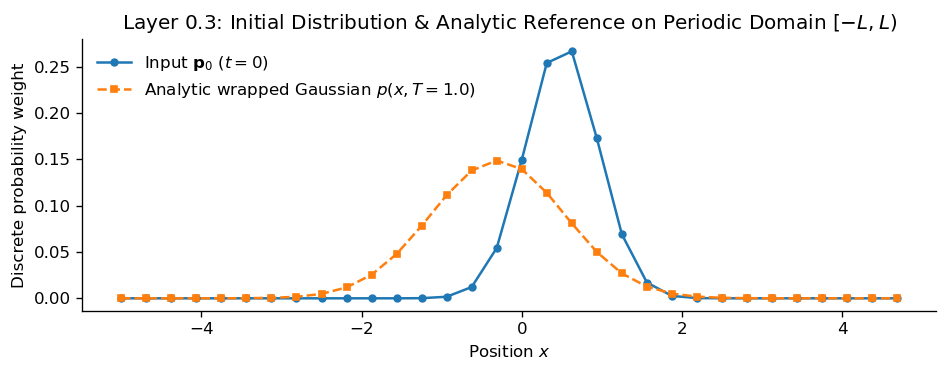

In [3]:
init_1d = layer_0_3_initial_and_analytic_distributions(config_1d, grid_1d)

print("=== Layer 0.3: Initial Distribution & Quantum State ===")
print(f"Initial center x0         = {init_1d['x0_vec']}, sigma0 = {config_1d.sigma0}")
print(f"||p0||_1  (Eq. 23 check)  = {init_1d['p0_l1_norm']:.15f}")
print(f"|||p0>||_2 (Eq. 6 check)  = {init_1d['ket_p0_l2_norm']:.15f}")
print(f"||p_exact(T)||_1          = {np.sum(init_1d['p_exact_T']):.15f}")
print(f"Peak shift: x(t=0) = {grid_1d['x_1d'][np.argmax(init_1d['p0'])]:.4f} -> x(t=T) = {grid_1d['x_1d'][np.argmax(init_1d['p_exact_T'])]:.4f} (expected x0 - a*T = {config_1d.x0[0] - config_1d.a*config_1d.T:.4f})")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(grid_1d["x_1d"], init_1d["p0"], "o-", ms=4, label=r"Input $\mathbf{p}_0$ ($t=0$)")
ax.plot(grid_1d["x_1d"], init_1d["p_exact_T"], "s--", ms=4, label=rf"Analytic wrapped Gaussian $p(x, T={config_1d.T})$")
ax.set_xlabel("Position $x$")
ax.set_ylabel("Discrete probability weight")
ax.set_title("Layer 0.3: Initial Distribution & Analytic Reference on Periodic Domain $[-L, L)$")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Layer 0.4 — Circulant Spatial Operators $\mathcal{H}$ (Eq. 26) and $\mathcal{M}$ (Eq. 28)
Constructs the 1D $n_x \times n_x$ periodic FTCS spatial operator $\mathcal{H}$ and extends it to $d$ dimensions via Kronecker sums:
$$\mathcal{M} = \sum_{j=1}^d \mathcal{I}_{n_x}^{\otimes (j-1)} \otimes \mathcal{H} \otimes \mathcal{I}_{n_x}^{\otimes (d-j)}$$

=== Layer 0.4: Spatial Operators H and M ===
H_1d shape = (32, 32), M shape = (32, 32)
Stencil weights: w_- (subdiag) = 1.280000, w_0 (diag) = -5.120000, w_+ (superdiag) = 3.840000
Row sum of H_1d (max |sum|) = 2.220e-16 (zero-sum generator)
Periodic corner check: H[0, -1] = 1.28 , H[-1, 0] = 3.84


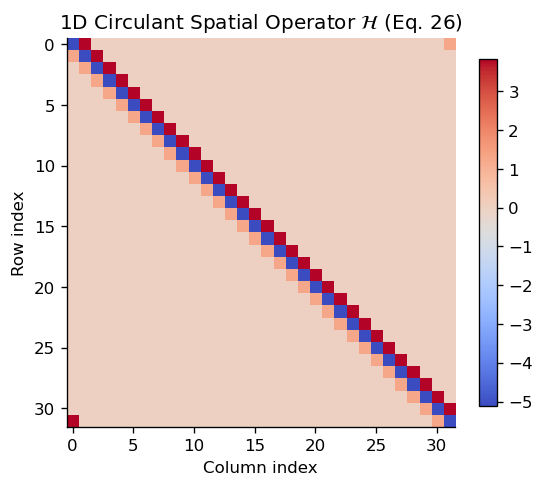

In [4]:
spatial_1d = layer_0_4_build_spatial_operators_H_and_M(config_1d, grid_1d)

print("=== Layer 0.4: Spatial Operators H and M ===")
print(f"H_1d shape = {spatial_1d['H_1d'].shape}, M shape = {spatial_1d['M'].shape}")
print(f"Stencil weights: w_- (subdiag) = {spatial_1d['w_minus']:.6f}, w_0 (diag) = {spatial_1d['w_center']:.6f}, w_+ (superdiag) = {spatial_1d['w_plus']:.6f}")
print(f"Row sum of H_1d (max |sum|) = {np.max(np.abs(spatial_1d['H_1d'].sum(axis=1))):.3e} (zero-sum generator)")
print("Periodic corner check: H[0, -1] =", spatial_1d["H_1d"][0, -1], ", H[-1, 0] =", spatial_1d["H_1d"][-1, 0])

fig, ax = plt.subplots(figsize=(4.8, 4.2))
im = ax.imshow(spatial_1d["H_1d"], cmap="coolwarm", aspect="equal")
ax.set_title(r"1D Circulant Spatial Operator $\mathcal{H}$ (Eq. 26)")
ax.set_xlabel("Column index")
ax.set_ylabel("Row index")
fig.colorbar(im, ax=ax, shrink=0.82)
plt.tight_layout()
plt.show()

### Layer 0.5 — Single-Step Transition Operator $\mathcal{L} = \mathcal{I}_{n_x^d} + \Delta t\mathcal{M}$ (Eqs. 16 & 29)
Verifies that under the Theorem 1 step-size restriction $\Delta t \le \frac{\Delta x^2}{2dD}$ (and $a\Delta x/(2D)\le 1$), $\mathcal{L}$ is **non-negative and doubly stochastic**, guaranteeing probability mass conservation $\|\mathcal{L}\mathbf{p}_0\|_1 = 1$.

In [5]:
L_info_1d = layer_0_5_build_transition_operator_L(config_1d, grid_1d, spatial_1d, init_info=init_1d)

print("=== Layer 0.5: Transition Operator L = I + dt * M ===")
print(f"L_op shape             = {L_info_1d['L_op'].shape}")
print(f"min(L_op)              = {L_info_1d['min_entry']:.6f} (>= 0)")
print(f"max |row_sum - 1|      = {L_info_1d['max_row_sum_err']:.3e}")
print(f"max |col_sum - 1|      = {L_info_1d['max_col_sum_err']:.3e}")
print(f"is_doubly_stochastic   = {L_info_1d['is_doubly_stochastic']}")
print(f"||L * p0||_1           = {L_info_1d['p1_l1_norm']:.15f}")
print("First row non-zero transition weights:", np.round(L_info_1d["L_op"][0, [0, 1, -1]], 6))

=== Layer 0.5: Transition Operator L = I + dt * M ===
L_op shape             = (32, 32)
min(L_op)              = 0.000000 (>= 0)
max |row_sum - 1|      = 0.000e+00
max |col_sum - 1|      = 0.000e+00
is_doubly_stochastic   = True
||L * p0||_1           = 1.000000000000000
First row non-zero transition weights: [0.872 0.096 0.032]


### Layer 0.6 — Space-Time Shift Matrix $\mathcal{T}$ (Eq. 31), Linear System $\mathcal{A}$ (Eqs. 17, 27, 30), and RHS $\mathbf{b}$
Constructs the $n_t \times n_t$ lower-bidiagonal matrix $\mathcal{T}$, builds $\mathcal{A} = \mathcal{T} \otimes \mathcal{L} - \Delta t\,\mathcal{I}_{n_t} \otimes \mathcal{M}$, verifies exact equality with the explicit block matrix in Eqs. (17)/(27), and forms $\mathbf{b} = (\mathcal{L}\mathbf{p}_0, \mathbf{0}, \dots, \mathbf{0})^T$.

=== Layer 0.6: Full Space-Time Linear System A * p = b ===
T_mat shape                  = (40, 40)
A_mat shape (nt*nx^d)^2      = (1280, 1280)
b_vec shape                  = (1280,)
Max |A_tensor - A_block_ref| = 0.000e+00
Max non-zeros per row of A   = 4 (sparsity s = O(d))


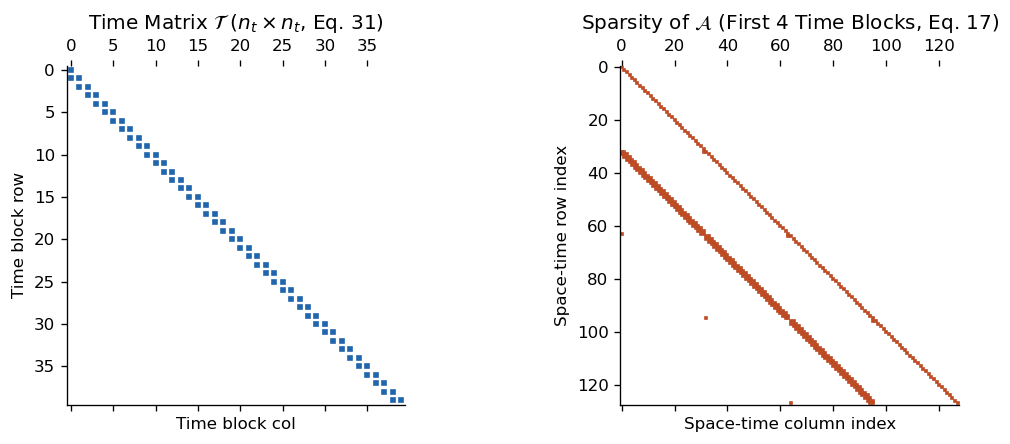

In [6]:
A_info_1d = layer_0_6_build_spacetime_system_A(grid_1d, spatial_1d, L_info_1d, init_1d)

print("=== Layer 0.6: Full Space-Time Linear System A * p = b ===")
print(f"T_mat shape                  = {A_info_1d['T_mat'].shape}")
print(f"A_mat shape (nt*nx^d)^2      = {A_info_1d['A_shape']}")
print(f"b_vec shape                  = {A_info_1d['b_vec'].shape}")
print(f"Max |A_tensor - A_block_ref| = {A_info_1d['tensor_vs_block_max_diff']:.3e}")
print(f"Max non-zeros per row of A   = {A_info_1d['max_nnz_per_row']} (sparsity s = O(d))")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.8))
ax1.spy(A_info_1d["T_mat"], markersize=2.5, color="#2166ac")
ax1.set_title(r"Time Matrix $\mathcal{T}$ ($n_t \times n_t$, Eq. 31)")
ax1.set_xlabel("Time block col")
ax1.set_ylabel("Time block row")

zoom = 4 * grid_1d["nx"]
ax2.spy(A_info_1d["A_mat"][:zoom, :zoom], markersize=1.2, color="#bc4b24")
ax2.set_title(r"Sparsity of $\mathcal{A}$ (First 4 Time Blocks, Eq. 17)")
ax2.set_xlabel("Space-time column index")
ax2.set_ylabel("Space-time row index")
plt.tight_layout()
plt.show()

### Layer 0.7 — Spectral Analysis, Condition Numbers & Lemma 12 Norm Bounds
Verifies every spectral theorem and lemma used across the classical and quantum algorithms:
* **Lemma 3 (Eq. 33):** $\mu_j = -\frac{4D}{\Delta x^2}\sin^2\left(\frac{\pi j}{n_x}\right) + i\frac{a}{\Delta x}\sin\left(\frac{2\pi j}{n_x}\right)$ and unitary DFT diagonalization $\mathcal{F}^\dagger \mathcal{H} \mathcal{F} = \text{diag}(\mu)$.
* **Lemma 4 (Eqs. 34–38):** Block reduction $\mathcal{A}_j \mathcal{A}_j^\dagger$ and secular equation $|l_j|\sin(n_t\theta) + \sin((n_t+1)\theta)=0$.
* **Theorem 5:** Singular value bounds and $\kappa_{\mathcal{A}} = \Theta(n_t)$.
* **Lemma 11 (Eqs. D1–D4):** $\kappa_{\mathcal{L}} \le 5$ when $Y \le 1/5, a/D < 2\sqrt{10}$.
* **Lemma 12 (Eq. 56):** $\|\mathcal{L}^\tau |0\rangle\|_2^2 \ge \frac{1}{(4\sqrt{\tau})^d}$ for $\tau = 1, \dots, n_t$.

=== Layer 0.7: Spectral & Conditioning Verification (1D) ===
Lemma 3 |F^dag H F - diag(mu)|_max       = 2.962e-14
Eq. (32) |F^dag L F - diag(l)|_max       = 3.131e-15
Lemma 4 |A_j A_j^dag numerical-formula|  = 2.221e-16
Lemma 4 secular roots max error          = 4.330e-14
Lemma 4 block SV vs full SVD(A) max err  = 1.665e-14
Lemma 11 SV formula vs SVD(L) max err    = 2.220e-16

Theorem 5: sigma_min(A) = 0.038783 >= 2/(nt*pi) = 0.015915
Theorem 5: sigma_max(A) = 1.998496 (||A^-1|| = 25.7847)
Theorem 5: kappa_A      = 51.5307 <= Thm 5 bound 80.0000
Lemma 11 : kappa_L      = 1.344086 <= 5.0 (formula: 1.344086)
Lemma 12 : ||L^tau |0>||_2^2 >= (4*sqrt(tau))^-d for all tau=1..nt : True


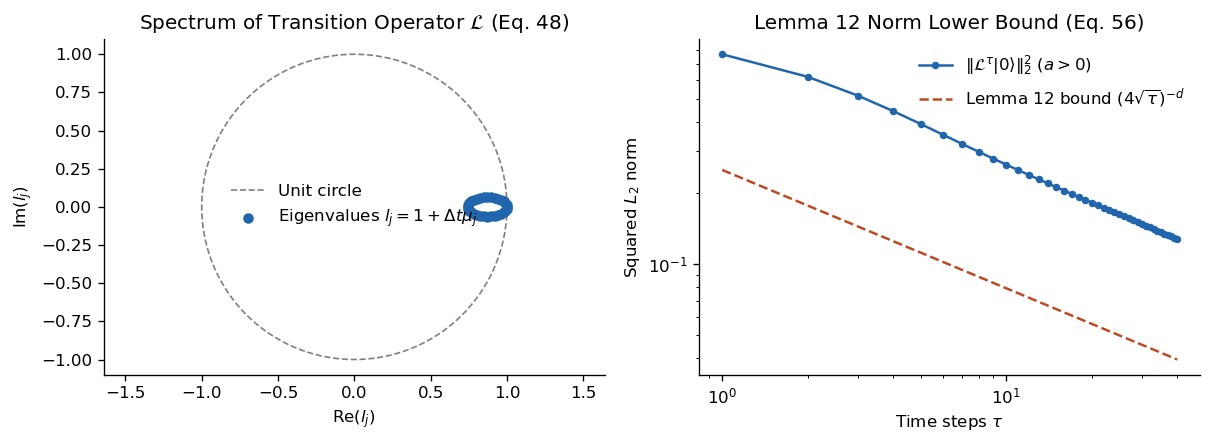

In [7]:
spectra_1d = layer_0_7_spectral_and_conditioning_analysis(
    config_1d, grid_1d, spatial_1d, L_info_1d, A_info_1d
)

print("=== Layer 0.7: Spectral & Conditioning Verification (1D) ===")
print(f"Lemma 3 |F^dag H F - diag(mu)|_max       = {spectra_1d['H_diag_err']:.3e}")
print(f"Eq. (32) |F^dag L F - diag(l)|_max       = {spectra_1d['L_diag_err']:.3e}")
print(f"Lemma 4 |A_j A_j^dag numerical-formula|  = {spectra_1d['block_AAdag_formula_err']:.3e}")
print(f"Lemma 4 secular roots max error          = {spectra_1d['secular_eq_max_err']:.3e}")
print(f"Lemma 4 block SV vs full SVD(A) max err  = {spectra_1d['svd_block_vs_full_err']:.3e}")
print(f"Lemma 11 SV formula vs SVD(L) max err    = {spectra_1d['L_singular_values_err']:.3e}")
print(f"\nTheorem 5: sigma_min(A) = {spectra_1d['sigma_min_A']:.6f} >= 2/(nt*pi) = {spectra_1d['sigma_min_lower_C1']:.6f}")
print(f"Theorem 5: sigma_max(A) = {spectra_1d['sigma_max_A']:.6f} (||A^-1|| = {spectra_1d['norm_A_inv']:.4f})")
print(f"Theorem 5: kappa_A      = {spectra_1d['kappa_A']:.4f} <= Thm 5 bound {spectra_1d['kappa_A_thm5_bound']:.4f}")
print(f"Lemma 11 : kappa_L      = {spectra_1d['kappa_L']:.6f} <= 5.0 (formula: {spectra_1d['kappa_L_1d_formula']:.6f})")
print(f"Lemma 12 : ||L^tau |0>||_2^2 >= (4*sqrt(tau))^-d for all tau=1..nt : {spectra_1d['lemma12_satisfied']}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.2, 3.8))
theta_unit = np.linspace(0, 2 * np.pi, 300)
ax1.plot(np.cos(theta_unit), np.sin(theta_unit), "--", color="gray", lw=1, label="Unit circle")
ax1.scatter(spectra_1d["l_1d"].real, spectra_1d["l_1d"].imag, color="#2166ac", s=28, zorder=3, label=r"Eigenvalues $l_j = 1 + \Delta t \mu_j$")
ax1.set_xlabel(r"$\mathrm{Re}(l_j)$")
ax1.set_ylabel(r"$\mathrm{Im}(l_j)$")
ax1.set_title(r"Spectrum of Transition Operator $\mathcal{L}$ (Eq. 48)")
ax1.axis("equal")
ax1.legend(frameon=False)

ax2.loglog(spectra_1d["taus"], spectra_1d["norm_L_tau_origin_sq"], "o-", ms=3.5, color="#2166ac", label=r"$\|\mathcal{L}^\tau |0\rangle\|_2^2$ ($a > 0$)")
ax2.loglog(spectra_1d["taus"], spectra_1d["lemma12_lower_bound"], "--", color="#bc4b24", label=r"Lemma 12 bound $(4\sqrt{\tau})^{-d}$")
ax2.set_xlabel(r"Time steps $\tau$")
ax2.set_ylabel("Squared $L_2$ norm")
ax2.set_title(r"Lemma 12 Norm Lower Bound (Eq. 56)")
ax2.legend(frameon=False)
plt.tight_layout()
plt.show()

### Layer 0.8 — Discretization Test Case Verification (1D & 2D Multi-Dimensional Readiness)
Assembles the shared `DDEDiscretization` objects for both:
1. **1D Test Case:** Solves $\mathcal{A}\tilde{\mathbf{p}} = \mathbf{b}$ and compares against $\mathcal{L}^{n_t}\mathbf{p}_0$ and the exact periodic solution $p(x, T)$, verifying $\|\tilde{\mathbf{p}}_{n_t} - \mathbf{p}_{n_t}\|_\infty \le E_{\text{Thm1}}$.
2. **2D Test Case ($d = 2, n_x = 12, n_t = 20$):** Runs the exact same discretization layers in $d=2$ dimensions, confirming Kronecker-sum scaling and full readiness for the Classical & Quantum solver modules.

=== 1D Discretization Test Case Verification ===
max |p_T(from A\b) - p_T(from L^nt p0)| = 2.776e-17
||p_T||_1 (mass conservation)           = 1.000000000000000
min(p_T) (positivity)                   = 1.914e-08
||p_tilde(T) - p_exact(T)||_inf         = 0.004301 <= Thm 1 bound (0.292920)



=== 2D Discretization Test Case Verification (d=2, nx=12, nt=20) ===
Space dimension n_x^d = 144, Space-time matrix A = (2880, 2880)
Stochastic stable = True, Lemma 11 satisfied = True
Lemma 3 |F^dag H F - diag(mu)| = 7.053e-15, Lemma 4 SVD err = 1.865e-14
max |p_T(from A\b) - p_T(from L^nt p0)| = 2.776e-17
||p_tilde(T) - p_exact(T)||_inf         = 0.007959 <= Thm 1 bound (0.185271)


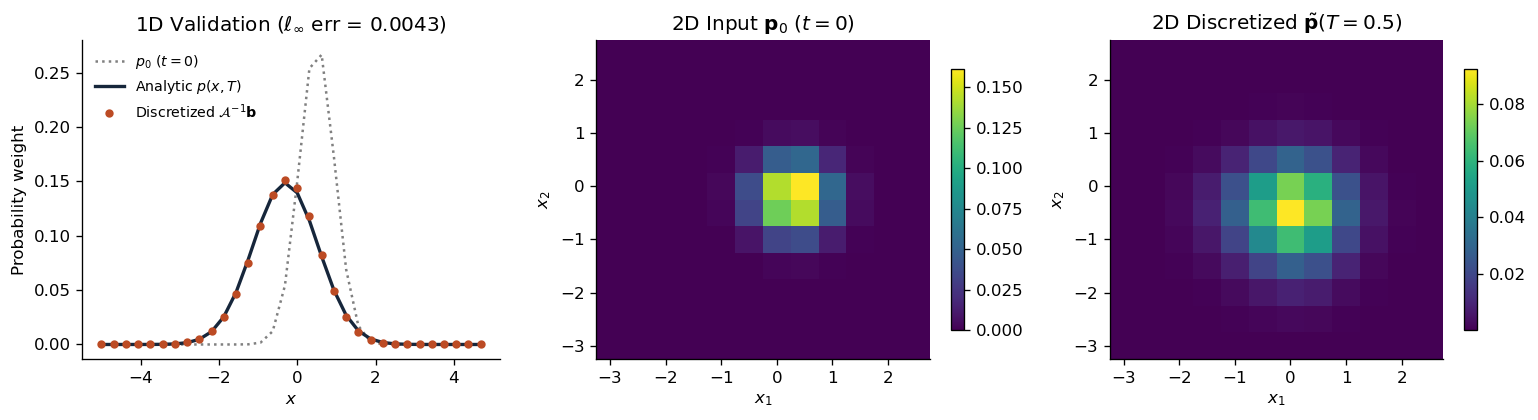

In [8]:
disc_1d = DDEDiscretization(
    config=config_1d,
    theory=theory_1d,
    dx=grid_1d["dx"],
    dt=grid_1d["dt"],
    nx=grid_1d["nx"],
    nt=grid_1d["nt"],
    stability_param=grid_1d["stability_param"],
    stochastic_stable=grid_1d["stochastic_stable"],
    lemma11_Y=grid_1d["lemma11_Y"],
    a_over_D=grid_1d["a_over_D"],
    lemma11_satisfied=grid_1d["lemma11_satisfied"],
    thm1_error_bound=grid_1d["thm1_error_bound"],
    x_1d=grid_1d["x_1d"],
    t_grid=grid_1d["t_grid"],
    coords_dd=grid_1d["coords_dd"],
    p0=init_1d["p0"],
    ket_p0=init_1d["ket_p0"],
    p_exact_T=init_1d["p_exact_T"],
    H_1d=spatial_1d["H_1d"],
    M=spatial_1d["M"],
    L_op=L_info_1d["L_op"],
    T_mat=A_info_1d["T_mat"],
    A_mat=A_info_1d["A_mat"],
    b_vec=A_info_1d["b_vec"],
    spectra=spectra_1d,
)
val_1d = verify_discretization_test_case(disc_1d)

print("=== 1D Discretization Test Case Verification ===")
print(f"max |p_T(from A\\b) - p_T(from L^nt p0)| = {val_1d['max_diff_A_vs_L']:.3e}")
print(f"||p_T||_1 (mass conservation)           = {val_1d['l1_final']:.15f}")
print(f"min(p_T) (positivity)                   = {val_1d['min_prob']:.3e}")
print(f"||p_tilde(T) - p_exact(T)||_inf         = {val_1d['err_inf_vs_exact']:.6f} <= Thm 1 bound ({val_1d['thm1_error_bound']:.6f})")

config_2d = DDEConfig(
    T=0.5,
    L=3.0,
    a=0.6,
    D=0.25,
    d=2,
    zeta=1.0,
    eps_c=0.05,
    eps_q=0.03,
    nx=12,
    nt=20,
    p0_type="gaussian",
    x0=[0.3, -0.2],
    sigma0=0.45,
)
disc_2d = disc_mod.assemble_discretization(config_2d)
val_2d = verify_discretization_test_case(disc_2d)

print("\n=== 2D Discretization Test Case Verification (d=2, nx=12, nt=20) ===")
print(f"Space dimension n_x^d = {disc_2d.nx**config_2d.d}, Space-time matrix A = {disc_2d.A_mat.shape}")
print(f"Stochastic stable = {disc_2d.stochastic_stable}, Lemma 11 satisfied = {disc_2d.lemma11_satisfied}")
print(f"Lemma 3 |F^dag H F - diag(mu)| = {disc_2d.spectra['H_diag_err']:.3e}, Lemma 4 SVD err = {disc_2d.spectra['svd_block_vs_full_err']:.3e}")
print(f"max |p_T(from A\\b) - p_T(from L^nt p0)| = {val_2d['max_diff_A_vs_L']:.3e}")
print(f"||p_tilde(T) - p_exact(T)||_inf         = {val_2d['err_inf_vs_exact']:.6f} <= Thm 1 bound ({val_2d['thm1_error_bound']:.6f})")

fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.6))
axes[0].plot(disc_1d.x_1d, disc_1d.p0, ":", color="gray", label=r"$p_0$ ($t=0$)")
axes[0].plot(disc_1d.x_1d, disc_1d.p_exact_T, "-", color="#16263b", lw=2, label="Analytic $p(x,T)$")
axes[0].plot(disc_1d.x_1d, val_1d["p_T_from_A"], "o", ms=4, color="#bc4b24", label=r"Discretized $\mathcal{A}^{-1}\mathbf{b}$")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("Probability weight")
axes[0].set_title(f"1D Validation ($\\ell_\\infty$ err = {val_1d['err_inf_vs_exact']:.4f})")
axes[0].legend(frameon=False, fontsize=8.5)

X_mesh, Y_mesh = np.meshgrid(disc_2d.x_1d, disc_2d.x_1d, indexing="ij")
p0_2d = disc_2d.p0.reshape(disc_2d.nx, disc_2d.nx)
pT_2d = val_2d["p_T_from_L"].reshape(disc_2d.nx, disc_2d.nx)

im1 = axes[1].pcolormesh(X_mesh, Y_mesh, p0_2d, shading="auto", cmap="viridis")
axes[1].set_title(r"2D Input $\mathbf{p}_0$ ($t=0$)")
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
fig.colorbar(im1, ax=axes[1], shrink=0.82)

im2 = axes[2].pcolormesh(X_mesh, Y_mesh, pT_2d, shading="auto", cmap="viridis")
axes[2].set_title(rf"2D Discretized $\tilde{{\mathbf{{p}}}}(T={config_2d.T})$")
axes[2].set_xlabel("$x_1$")
axes[2].set_ylabel("$x_2$")
fig.colorbar(im2, ax=axes[2], shrink=0.82)

plt.tight_layout()
plt.show()

---
## Step 2: The Four Classical Algorithms (`classical_solvers.py`, Section III)
Each stage of **Figs. 1–4** executes in its own dedicated cell.

### C1 — Classical Linear Equations (Fig. 1, Theorem 6)
#### C1 Stage 1: Build RHS Vector $\mathbf{b} = (\mathcal{L}\mathbf{p}_0, \mathbf{0}, \dots, \mathbf{0})^T$

In [ ]:
import complete_code.classical_solvers as cs

c1_s1 = cs.c1_stage1_build_rhs(disc_1d)
print("=== C1 Stage 1: Build RHS vector b ===")
print(f"b_vec shape            = {c1_s1['b_vec'].shape}")
print(f"||b||_2                = {c1_s1['b_norm_2']:.6f}")
print(f"||L*p0||_1 (block 0)   = {np.sum(np.abs(c1_s1['Lp0'])):.15f}")
print(f"Max diff vs disc.b_vec = {c1_s1['max_diff_from_disc_b']:.3e}")

=== C1 Stage 1: Build RHS vector b ===
b_vec shape            = (1280,)
||b||_2                = 0.436431
||L*p0||_1 (block 0)   = 1.000000000000000
Max diff vs disc.b_vec = 0.000e+00


#### C1 Stage 2: Choose Accuracy $\delta = \Theta(\epsilon_c / n_t)$ & Set Up SPD Normal System

In [10]:
c1_s2 = cs.c1_stage2_choose_delta_and_setup_normal_system(disc_1d, c1_s1)
print("=== C1 Stage 2: Tolerance Selection & Sparse SPD Normal System ===")
print(f"Target tolerance delta = eps_c / nt = {c1_s2['delta']:.6f}")
print(f"Linear system size N = nt * nx^d    = {c1_s2['system_size']}")
print(f"Non-zeros in sparse A               = {c1_s2['nnz_A']} (avg {c1_s2['nnz_A']/c1_s2['system_size']:.2f} per row)")

=== C1 Stage 2: Tolerance Selection & Sparse SPD Normal System ===
Target tolerance delta = eps_c / nt = 0.001250
Linear system size N = nt * nx^d    = 1280
Non-zeros in sparse A               = 5024 (avg 3.92 per row)


#### C1 Stage 3: Execute Conjugate Gradient Solver (Full Space-Time Solution)

=== C1 Stage 3: Conjugate Gradient Convergence & Solution ===
CG converged = True in 121 iterations
Final ||A*x - b||_2          = 1.239695e-03 <= delta (1.250000e-03)
||x_CG - A^-1 b||_2          = 2.317248e-02
||p_CG(T) - p_direct(T)||_inf= 1.904461e-03
||p_CG(T) - p_exact(T)||_inf = 0.004468


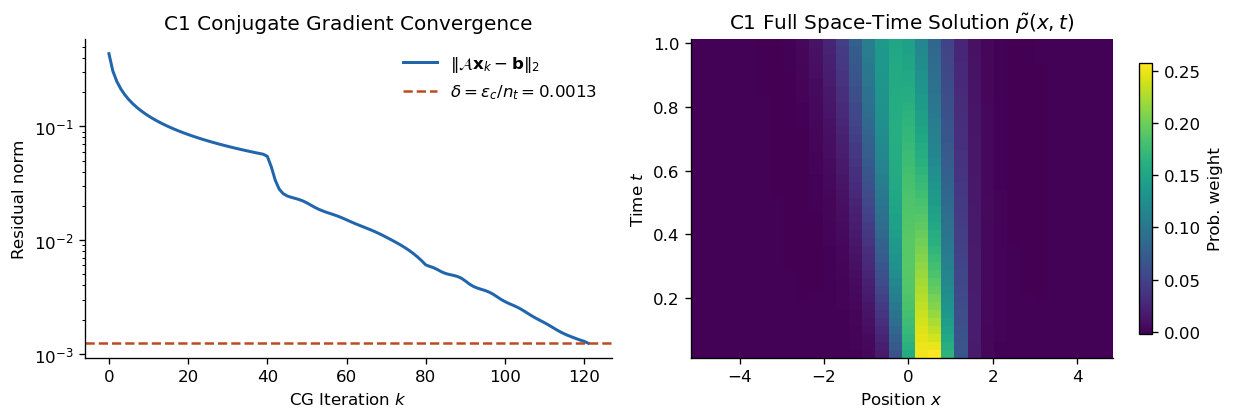

In [11]:
c1_s3 = cs.c1_stage3_conjugate_gradient_solve(disc_1d, c1_s2)

print("=== C1 Stage 3: Conjugate Gradient Convergence & Solution ===")
print(f"CG converged = {c1_s3['converged']} in {c1_s3['iterations']} iterations")
print(f"Final ||A*x - b||_2          = {c1_s3['final_orig_residual']:.6e} <= delta ({c1_s3['target_tol']:.6e})")
print(f"||x_CG - A^-1 b||_2          = {c1_s3['solver_err_2_vs_direct']:.6e}")
print(f"||p_CG(T) - p_direct(T)||_inf= {c1_s3['solver_err_inf_vs_direct']:.6e}")
print(f"||p_CG(T) - p_exact(T)||_inf = {c1_s3['err_inf_vs_exact']:.6f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax1.semilogy(c1_s3["res_orig_history"], color="#2166ac", lw=1.8, label=r"$\|\mathcal{A}\mathbf{x}_k - \mathbf{b}\|_2$")
ax1.axhline(c1_s3["target_tol"], ls="--", color="#bc4b24", label=rf"$\delta = \epsilon_c/n_t = {c1_s3['target_tol']:.4f}$")
ax1.set_xlabel("CG Iteration $k$")
ax1.set_ylabel("Residual norm")
ax1.set_title("C1 Conjugate Gradient Convergence")
ax1.legend(frameon=False)

im = ax2.pcolormesh(disc_1d.x_1d, disc_1d.t_grid[1:], c1_s3["p_spacetime"], shading="auto", cmap="viridis")
ax2.set_xlabel("Position $x$")
ax2.set_ylabel("Time $t$")
ax2.set_title(r"C1 Full Space-Time Solution $\tilde{p}(x, t)$")
fig.colorbar(im, ax=ax2, shrink=0.85, label="Prob. weight")
plt.tight_layout()
plt.show()

### C2 — Classical Time-Evolution Method (Fig. 2, Theorem 7)
#### C2 Stage 1: Single-Step Operator Application $\tilde{\mathbf{p}}_1 = \mathcal{L}\mathbf{p}_0$

In [12]:
c2_s1 = cs.c2_stage1_apply_single_step_L(disc_1d)
print("=== C2 Stage 1: Single Time Step p1 = L * p0 ===")
print(f"||p1||_1 = {c2_s1['l1_norm_p1']:.15f}")
print(f"min(p1)  = {c2_s1['min_p1']:.3e}")
print(f"max(p1)  = {np.max(c2_s1['p1']):.6f}")

=== C2 Stage 1: Single Time Step p1 = L * p0 ===
||p1||_1 = 1.000000000000000
min(p1)  = 1.276e-24
max(p1)  = 0.257147


#### C2 Stage 2: Iterate $\mathcal{L}$ for $n_t$ Steps ($O(d n_t n_x^d)$)

=== C2 Stage 2: Full nt-Step Time Evolution ===
Trajectory shape       = (41, 32)
Max | ||p_k||_1 - 1 |  = 2.220e-16
||p_C2(T) - p_exact(T)||_inf = 0.004301


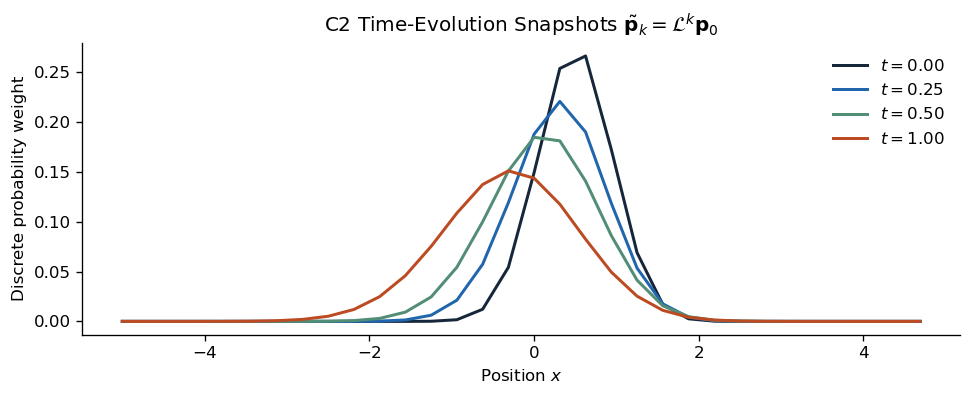

In [13]:
c2_s2 = cs.c2_stage2_repeat_nt_steps(disc_1d, c2_s1)
print("=== C2 Stage 2: Full nt-Step Time Evolution ===")
print(f"Trajectory shape       = {c2_s2['trajectory'].shape}")
print(f"Max | ||p_k||_1 - 1 |  = {c2_s2['max_l1_drift']:.3e}")
print(f"||p_C2(T) - p_exact(T)||_inf = {c2_s2['err_inf_vs_exact']:.6f}")

fig, ax = plt.subplots(figsize=(8.2, 3.4))
for step_idx, color in [(0, "#16263b"), (disc_1d.nt // 4, "#2166ac"), (disc_1d.nt // 2, "#528d75"), (disc_1d.nt, "#bc4b24")]:
    ax.plot(disc_1d.x_1d, c2_s2["trajectory"][step_idx], color=color, lw=1.8, label=rf"$t = {disc_1d.t_grid[step_idx]:.2f}$")
ax.set_xlabel("Position $x$")
ax.set_ylabel("Discrete probability weight")
ax.set_title(r"C2 Time-Evolution Snapshots $\tilde{\mathbf{p}}_k = \mathcal{L}^k \mathbf{p}_0$")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### C3 — Classical Random Walk via CFTP Exact Sampling (Fig. 3, Theorem 8)
#### C3 Stage 1: Extract Markov Random-Walk Kernel from $\mathcal{L}$

In [14]:
c3_s1 = cs.c3_stage1_extract_markov_kernel(disc_1d)
print("=== C3 Stage 1: Markov Random-Walk Kernel from L ===")
print(f"p_stay         = {c3_s1['p_stay']:.6f}")
print(f"p_- (-dx step) = {c3_s1['p_minus']:.6f}  (drift -a moves left)")
print(f"p_+ (+dx step) = {c3_s1['p_plus']:.6f}")
print(f"Sum of probs   = {c3_s1['probs'].sum():.15f}")
print(f"Max |L_kernel - disc.L_op| = {c3_s1['kernel_vs_L_err']:.3e}")

=== C3 Stage 1: Markov Random-Walk Kernel from L ===
p_stay         = 0.872000
p_- (-dx step) = 0.096000  (drift -a moves left)
p_+ (+dx step) = 0.032000
Sum of probs   = 1.000000000000000
Max |L_kernel - disc.L_op| = 0.000e+00


#### C3 Stage 2: Coupled Random-Walk Mapping over Hitting Horizon $H = n_t$ (Fig. 3 Stage 1)

=== C3 Stage 2: Single Coupled Horizon H = nt Mapping ===
Total lattice displacement after nt=40 steps = [-4] grid cells
Sample coupled map (first 8 indices -> mapped): [(0, 28), (1, 29), (2, 30), (3, 31), (4, 0), (5, 1), (6, 2), (7, 3)]


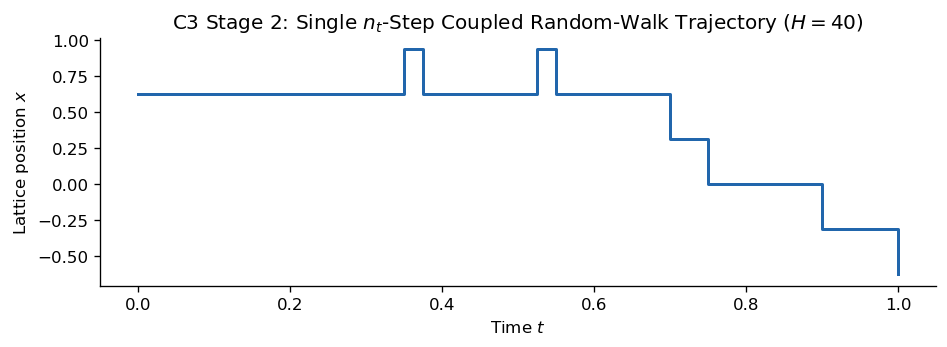

In [15]:
c3_s2 = cs.c3_stage2_cftp_single_coupled_horizon(disc_1d, c3_s1, seed=313)
print("=== C3 Stage 2: Single Coupled Horizon H = nt Mapping ===")
print(f"Total lattice displacement after nt={disc_1d.nt} steps = {c3_s2['total_shift']} grid cells")
print(f"Sample coupled map (first 8 indices -> mapped): {list(zip(range(8), c3_s2['coupled_map'][:8].tolist()))}")

fig, ax = plt.subplots(figsize=(8.0, 3.0))
ax.step(disc_1d.t_grid, disc_1d.x_1d[c3_s2["rep_path_flat"]], where="post", color="#2166ac", lw=1.8)
ax.set_xlabel("Time $t$")
ax.set_ylabel("Lattice position $x$")
ax.set_title(rf"C3 Stage 2: Single $n_t$-Step Coupled Random-Walk Trajectory ($H = {disc_1d.nt}$)")
plt.tight_layout()
plt.show()

#### C3 Stage 3: Repeat Exact Sampling Across All $n_x^d$ Grid Points (Fig. 3 Stage 2, Theorem 8)

=== C3 Stage 3: Random-Walk Exact Pushforward & Sampling Convergence ===
Max |exact_pushforward - L^nt p0|       = 2.220e-16
Empirical RW (M=128000) ||p||_1      = 1.000000000000000
Empirical RW ||p_RW - L^nt p0||_inf     = 0.000800
Empirical RW ||p_RW - p_exact(T)||_inf  = 0.004340
Log-log sampling error slope vs M       = -0.628 (theory: -0.500)


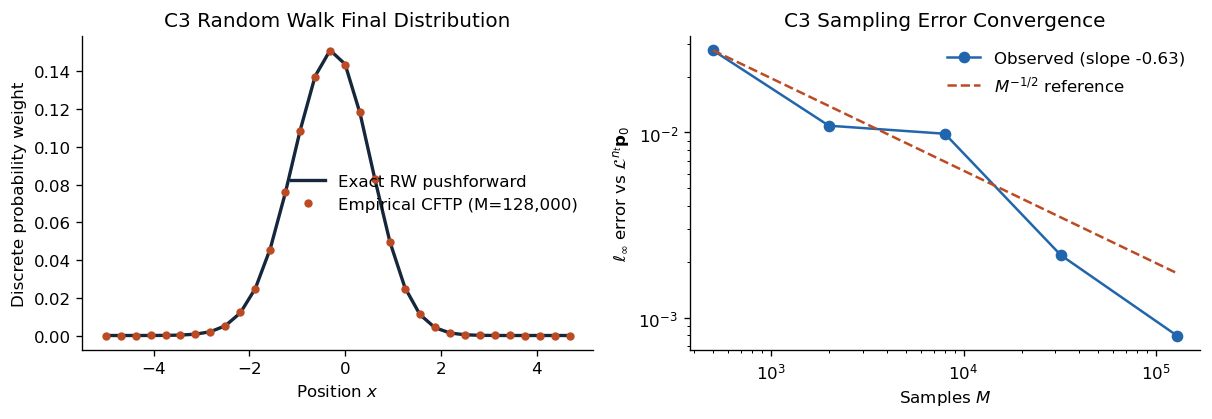

In [16]:
c3_s3 = cs.c3_stage3_repeat_across_grid_and_aggregate(
    disc_1d, c3_s1, samples_per_grid_list=(500, 2000, 8000, 32000, 128000), seed=313
)
print("=== C3 Stage 3: Random-Walk Exact Pushforward & Sampling Convergence ===")
print(f"Max |exact_pushforward - L^nt p0|       = {np.max(np.abs(c3_s3['exact_markov_pushforward'] - c2_s2['p_T'])):.3e}")
print(f"Empirical RW (M={c3_s3['finest_M']}) ||p||_1      = {c3_s3['l1_norm_empirical']:.15f}")
print(f"Empirical RW ||p_RW - L^nt p0||_inf     = {c3_s3['err_inf_vs_L_by_M'][c3_s3['finest_M']]:.6f}")
print(f"Empirical RW ||p_RW - p_exact(T)||_inf  = {c3_s3['err_inf_vs_exact_by_M'][c3_s3['finest_M']]:.6f}")
print(f"Log-log sampling error slope vs M       = {c3_s3['sampling_slope']:.3f} (theory: -0.500)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.2, 3.6))
ax1.plot(disc_1d.x_1d, c3_s3["exact_markov_pushforward"], "-", color="#16263b", lw=2, label="Exact RW pushforward")
ax1.plot(disc_1d.x_1d, c3_s3["p_T_empirical"], "o", ms=4, color="#bc4b24", label=f"Empirical CFTP (M={c3_s3['finest_M']:,})")
ax1.set_xlabel("Position $x$")
ax1.set_ylabel("Discrete probability weight")
ax1.set_title("C3 Random Walk Final Distribution")
ax1.legend(frameon=False)

M_vals = c3_s3["M_values"]
errs = c3_s3["emp_errors_vs_L"]
ax2.loglog(M_vals, errs, "o-", color="#2166ac", label=f"Observed (slope {c3_s3['sampling_slope']:.2f})")
ax2.loglog(M_vals, errs[0] * np.sqrt(M_vals[0] / M_vals), "--", color="#bc4b24", label=r"$M^{-1/2}$ reference")
ax2.set_xlabel("Samples $M$")
ax2.set_ylabel(r"$\ell_\infty$ error vs $\mathcal{L}^{n_t}\mathbf{p}_0$")
ax2.set_title("C3 Sampling Error Convergence")
ax2.legend(frameon=False)
plt.tight_layout()
plt.show()

### C4 — Classical Diagonalization by Fast Fourier Transform (Fig. 4, Lemma 9, Theorem 10)
#### C4 Stage 1: Choose $\delta = O(\epsilon_c)$ and Determine Taylor Order $K = O(\log(n_t / \delta))$

In [17]:
c4_s1 = cs.c4_stage1_choose_delta(disc_1d)
print("=== C4 Stage 1: Eigenvalue Accuracy delta & Taylor Truncation Order (Lemma 9) ===")
print(f"Overall delta = eps_c          = {c4_s1['delta']:.6f}")
print(f"Per-step delta' = delta / nt   = {c4_s1['delta_prime']:.6e}")
print(f"Required sin accuracy          = {c4_s1['required_sin_accuracy']:.3e}")
print(f"Selected Taylor order K        = {c4_s1['taylor_terms_K']} terms (remainder bound {c4_s1['taylor_remainder_bound']:.3e})")

=== C4 Stage 1: Eigenvalue Accuracy delta & Taylor Truncation Order (Lemma 9) ===
Overall delta = eps_c          = 0.050000
Per-step delta' = delta / nt   = 1.250000e-03
Required sin accuracy          = 2.170e-03
Selected Taylor order K        = 10 terms (remainder bound 1.131e-03)


#### C4 Stage 2: Apply $d$-Dimensional FFT $\mathbf{p}_0 \mapsto \boldsymbol{\psi}_0$ (Fig. 4 Stage 2)

In [18]:
c4_s2 = cs.c4_stage2_fft_initial_state(disc_1d)
print("=== C4 Stage 2: Forward FFT of Initial State p0 ===")
print(f"Grid shape      = {c4_s2['shape_dd']}")
print(f"psi0[0] (DC mode)= {c4_s2['psi0'].ravel()[0]:.15f}  (equals ||p0||_1 = 1)")
print(f"max |psi0|      = {np.max(np.abs(c4_s2['psi0'])):.6f}")

=== C4 Stage 2: Forward FFT of Initial State p0 ===
Grid shape      = (32,)
psi0[0] (DC mode)= 1.000000000000000+0.000000000000000j  (equals ||p0||_1 = 1)
max |psi0|      = 1.000000


#### C4 Stage 3: Build $\Lambda^{n_t}$ (Lemma 9) and Evolve $\boldsymbol{\psi}_{n_t} = \Lambda^{n_t}\boldsymbol{\psi}_0$ (Fig. 4 Stage 3)

In [19]:
c4_s3 = cs.c4_stage3_build_eigenvalues_and_apply_Lambda_nt(disc_1d, c4_s1, c4_s2)
print("=== C4 Stage 3: Build Lambda^{nt} & Advance Fourier Modes ===")
print(f"||Lambda_tilde^nt - Lambda_exact^nt||_max = {c4_s3['lambda_nt_max_diff']:.3e} <= delta ({c4_s1['delta']}) -> {c4_s3['lemma9_bound_ok']}")
print(f"DC eigenvalue l_0^nt                      = {c4_s3['Lambda_nt_taylor'].ravel()[0]:.15f}")
print(f"||psi_nt||_2                              = {np.linalg.norm(c4_s3['psi_nt_taylor']):.6f}")

=== C4 Stage 3: Build Lambda^{nt} & Advance Fourier Modes ===
||Lambda_tilde^nt - Lambda_exact^nt||_max = 1.261e-03 <= delta (0.05) -> True
DC eigenvalue l_0^nt                      = 1.000000000000000+0.000000000000000j
||psi_nt||_2                              = 1.848490


#### C4 Stage 4: Apply Inverse FFT $\boldsymbol{\psi}_{n_t} \mapsto \tilde{\mathbf{p}}_{n_t}$ (Fig. 4 Stage 4, Eq. 51)

In [20]:
c4_s4 = cs.c4_stage4_ifft_reconstruction(disc_1d, c4_s1, c4_s3)
print("=== C4 Stage 4: Inverse FFT Reconstruction & Eq. (52) Check ===")
print(f"Eq. (52) ||p_Taylor - p_exact_trig||_2 = {c4_s4['eq52_l2_diff']:.3e} <= delta ({c4_s4['eq52_delta']}) -> {c4_s4['eq52_bound_ok']}")
print(f"max |p_C4(exact trig) - p_C2(L^nt)|    = {np.max(np.abs(c4_s4['p_T_exact_trig'] - c2_s2['p_T'])):.3e}")
print(f"||p_C4||_1                             = {c4_s4['l1_norm_T']:.15f}")
print(f"||p_C4(T) - p_exact(T)||_inf           = {c4_s4['err_inf_vs_exact']:.6f}")

=== C4 Stage 4: Inverse FFT Reconstruction & Eq. (52) Check ===
Eq. (52) ||p_Taylor - p_exact_trig||_2 = 1.605e-04 <= delta (0.05) -> True
max |p_C4(exact trig) - p_C2(L^nt)|    = 2.220e-16
||p_C4||_1                             = 1.000076002586216
||p_C4(T) - p_exact(T)||_inf           = 0.004288


### Step 2 Summary — End-to-End Classical Comparison (1D & 2D)

In [21]:
res_c_2d = cs.run_all_classical_solvers(disc_2d, samples_per_grid_list=(500, 2000, 8000, 32000))

print("=== 1D Classical Methods Accuracy Comparison (eps_c = 0.05) ===")
methods_1d = [
    ("C1: Linear Eqs (CG)", c1_s3["p_T"], c1_s3["err_inf_vs_exact"]),
    ("C2: Time Evolution",  c2_s2["p_T"], c2_s2["err_inf_vs_exact"]),
    ("C3: Random Walk",     c3_s3["p_T_empirical"], c3_s3["err_inf_vs_exact_by_M"][c3_s3["finest_M"]]),
    ("C4: FFT Diag",        c4_s4["p_T"], c4_s4["err_inf_vs_exact"]),
]
for name, vec, err_exact in methods_1d:
    diff_c2 = float(np.max(np.abs(vec - c2_s2["p_T"])))
    print(f"  {name:22s} | ||p - p_C2||_inf = {diff_c2:.3e} | ||p - p_exact||_inf = {err_exact:.6f}")

print("\n=== 2D Classical Methods Accuracy Comparison (d=2, nx=12, nt=20) ===")
ref_2d = res_c_2d["C2_time_evolution"]["p_T"]
for label, key in [("C1: Linear Eqs (CG)", "C1_linear_cg"), ("C2: Time Evolution", "C2_time_evolution"), ("C3: Random Walk", "C3_random_walk"), ("C4: FFT Diag", "C4_fft")]:
    vec2 = res_c_2d[key]["p_T"] if key != "C3_random_walk" else res_c_2d[key]["p_T_empirical"]
    err_ex2 = float(np.max(np.abs(vec2 - disc_2d.p_exact_T)))
    diff_c2_2d = float(np.max(np.abs(vec2 - ref_2d)))
    print(f"  {label:22s} | ||p - p_C2||_inf = {diff_c2_2d:.3e} | ||p - p_exact||_inf = {err_ex2:.6f}")

=== 1D Classical Methods Accuracy Comparison (eps_c = 0.05) ===
  C1: Linear Eqs (CG)    | ||p - p_C2||_inf = 1.904e-03 | ||p - p_exact||_inf = 0.004468
  C2: Time Evolution     | ||p - p_C2||_inf = 0.000e+00 | ||p - p_exact||_inf = 0.004301
  C3: Random Walk        | ||p - p_C2||_inf = 7.997e-04 | ||p - p_exact||_inf = 0.004340
  C4: FFT Diag           | ||p - p_C2||_inf = 4.370e-05 | ||p - p_exact||_inf = 0.004288

=== 2D Classical Methods Accuracy Comparison (d=2, nx=12, nt=20) ===
  C1: Linear Eqs (CG)    | ||p - p_C2||_inf = 1.133e-03 | ||p - p_exact||_inf = 0.007740
  C2: Time Evolution     | ||p - p_C2||_inf = 0.000e+00 | ||p - p_exact||_inf = 0.007959
  C3: Random Walk        | ||p - p_C2||_inf = 2.899e-03 | ||p - p_exact||_inf = 0.009238
  C4: FFT Diag           | ||p - p_C2||_inf = 2.077e-06 | ||p - p_exact||_inf = 0.007958


---
## Step 3: Multidimensional Quantum Measurement Protocol (`quantum_measurement.py`, Section IV.A.1, Theorem 16)
Demonstrates **every single layer** of the multidimensional amplitude estimation readout protocol (Lemmas 13–15, Theorem 16, Eqs. 57–60) using Qiskit `QuantumCircuit` and `Statevector` primitives on the target evolved quantum state $|\tilde{p}_{n_t}\rangle$:
1. **QM Layer 1 (Lemma 15):** Sample $N = O(\log(n/\delta)/\epsilon_q)$ shots from $|\tilde{p}\rangle$ to discover the heavy support $S = \{i : \tilde{p}_i \ge \epsilon_q\}$ of size $r \le \lceil 1/\epsilon_q \rceil$.
2. **QM Layer 2 (Eq. 57):** Construct $r$ Qiskit phase-estimation registers of $\tilde{k} = \lceil\log_2(4/\epsilon_q)\rceil$ qubits in Hadamard superposition.
3. **QM Layer 3 (Lemmas 13–14, Eqs. 58–60):** Apply Qiskit phase kickback $e^{2\pi i x_j \tilde{p}_{S_j}}$ across each register.
4. **QM Layer 4 (Theorem 16 Step 5):** Apply `QFTGate(k_tilde).inverse()` to each register, repeat $R = O(\log(1/(\delta\epsilon_q)))$ times, and take the coordinate-wise median to obtain $\tilde{\tilde{\mathbf{p}}}$ within $\epsilon_q$.

### QM Layer 1 — Threshold Coordinate Sampling (Lemma 15 & Theorem 16 Step 1)

In [ ]:
import complete_code.quantum_measurement as qm

pT_ref_1d = c2_s2["p_T"]
pT_norm2_1d = float(np.linalg.norm(pT_ref_1d, ord=2))
ket_pT_ref_1d = pT_ref_1d / pT_norm2_1d

qm_l1 = qm.qm_layer1_threshold_coordinate_sampling(
    ket_pT_ref_1d, p_norm2=pT_norm2_1d, eps_q=config_1d.eps_q, delta=0.01, seed=313
)
print("=== QM Layer 1: Lemma 15 Heavy-Coordinate Discovery ===")
print(f"Total grid size n         = {qm_l1['n_coords']}")
print(f"Shots drawn N             = {qm_l1['n_samples']}")
print(f"Active coordinates r=|S|  = {qm_l1['r_active']} <= ceil(1/eps_q) = {qm_l1['max_allowed_r']}")
print(f"Active indices S          = {qm_l1['active_indices'].tolist()}")
print(f"All heavy coords (>=eps_q) found? {qm_l1['all_heavy_discovered']}")
print(f"Max truncated weight      = {qm_l1['truncation_err_inf']:.6f} (< eps_q = {config_1d.eps_q})")

=== QM Layer 1: Lemma 15 Heavy-Coordinate Discovery ===
Total grid size n         = 32
Shots drawn N             = 473
Active coordinates r=|S|  = 7 <= ceil(1/eps_q) = 20
Active indices S          = [12, 13, 14, 15, 16, 17, 18]
All heavy coords (>=eps_q) found? True
Max truncated weight      = 0.049507 (< eps_q = 0.05)


### QM Layer 2 — Build $r$ Hadamard Phase-Estimation Registers (Theorem 16 Steps 2–3, Eq. 57)

In [23]:
qm_l2 = qm.qm_layer2_build_hadamard_registers(qm_l1, eps_q=config_1d.eps_q)
print("=== QM Layer 2: Hadamard Registers (Qiskit Circuits) ===")
print(f"Qubits per register k_tilde = {qm_l2['tilde_k']} (2^k_tilde = {qm_l2['dim_reg']})")
print(f"Active registers r          = {qm_l2['r_active']}, Total estimation qubits = {qm_l2['total_ancilla_qubits']}")
print(f"Phase resolution 4 / 2^k    = {qm_l2['phase_resolution']:.6f} <= eps_q ({config_1d.eps_q})")
print("\nSample Qiskit Hadamard register circuit (register 0):")
print(qm_l2["hadamard_circuits"][0].draw(output="text"))

=== QM Layer 2: Hadamard Registers (Qiskit Circuits) ===
Qubits per register k_tilde = 7 (2^k_tilde = 128)
Active registers r          = 7, Total estimation qubits = 49
Phase resolution 4 / 2^k    = 0.031250 <= eps_q (0.05)

Sample Qiskit Hadamard register circuit (register 0):
     ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     ├───┤
q_2: ┤ H ├
     ├───┤
q_3: ┤ H ├
     ├───┤
q_4: ┤ H ├
     ├───┤
q_5: ┤ H ├
     ├───┤
q_6: ┤ H ├
     └───┘


### QM Layer 3 — Phase Oracle Query Encoding $e^{2\pi i x_j \tilde{p}_{S_j}}$ (Lemmas 13–14, Eqs. 58–60)

In [24]:
qm_l3 = qm.qm_layer3_phase_oracle_query(qm_l1, qm_l2, eps_q=config_1d.eps_q)
print("=== QM Layer 3: Phase Oracle Query (Eq. 60) ===")
print(f"Max state error vs ideal Eq. (60) product state = {qm_l3['max_oracle_state_err']:.3e}")
print(f"Theorem 16 U_p query bound order                = {qm_l3['theorem16_Up_calls_order']}")
print("\nQiskit Phase-Kickback circuit for heaviest active coordinate:")
peak_reg_pos = int(np.argmax(qm_l1["p_tilde_ref"][qm_l1["active_indices"]]))
print(qm_l3["phase_circuits"][peak_reg_pos].draw(output="text"))

=== QM Layer 3: Phase Oracle Query (Eq. 60) ===
Max state error vs ideal Eq. (60) product state = 1.721e-15
Theorem 16 U_p query bound order                = 1227

Qiskit Phase-Kickback circuit for heaviest active coordinate:
     ┌───┐┌────────────┐
q_0: ┤ H ├┤ P(0.94986) ├
     ├───┤├───────────┬┘
q_1: ┤ H ├┤ P(1.8997) ├─
     ├───┤├───────────┤ 
q_2: ┤ H ├┤ P(3.7994) ├─
     ├───┤├───────────┤ 
q_3: ┤ H ├┤ P(7.5988) ├─
     ├───┤├───────────┤ 
q_4: ┤ H ├┤ P(15.198) ├─
     ├───┤├───────────┤ 
q_5: ┤ H ├┤ P(30.395) ├─
     ├───┤├───────────┤ 
q_6: ┤ H ├┤ P(60.791) ├─
     └───┘└───────────┘ 


### QM Layer 4 — Inverse QFT (`QFTGate.inverse()`) & Median Amplification (Theorem 16 Step 5)

=== QM Layer 4: IQFT Readout & Median Extraction ===
Median repetitions per coordinate R = 31
||p_tilde_tilde - p_tilde||_inf     = 0.049507 <= eps_q (0.05) -> True
||p_tilde_tilde - p_tilde||_2       = 0.078782


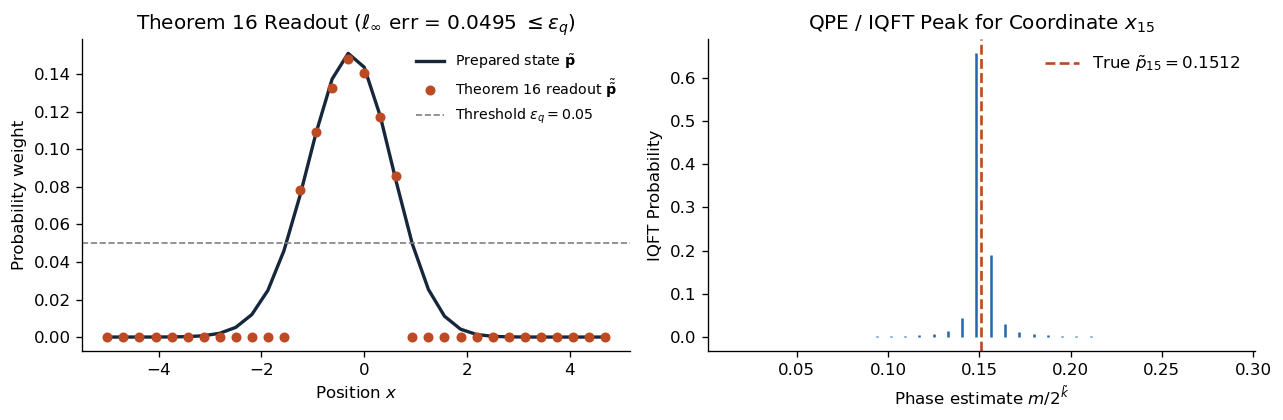

In [25]:
qm_l4 = qm.qm_layer4_iqft_and_median_extraction(
    qm_l1, qm_l2, qm_l3, eps_q=config_1d.eps_q, delta=0.01, seed=313
)
print("=== QM Layer 4: IQFT Readout & Median Extraction ===")
print(f"Median repetitions per coordinate R = {qm_l4['num_median_reps']}")
print(f"||p_tilde_tilde - p_tilde||_inf     = {qm_l4['err_inf_vs_ptilde']:.6f} <= eps_q ({config_1d.eps_q}) -> {qm_l4['within_eps_q']}")
print(f"||p_tilde_tilde - p_tilde||_2       = {qm_l4['err_2_vs_ptilde']:.6f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 3.6))
ax1.plot(disc_1d.x_1d, pT_ref_1d, "-", color="#16263b", lw=2, label=r"Prepared state $\tilde{\mathbf{p}}$")
ax1.plot(disc_1d.x_1d, qm_l4["p_extracted"], "o", ms=5, color="#bc4b24", label=r"Theorem 16 readout $\tilde{\tilde{\mathbf{p}}}$")
ax1.axhline(config_1d.eps_q, ls="--", color="gray", lw=1, label=rf"Threshold $\epsilon_q = {config_1d.eps_q}$")
ax1.set_xlabel("Position $x$")
ax1.set_ylabel("Probability weight")
ax1.set_title(rf"Theorem 16 Readout ($\ell_\infty$ err = {qm_l4['err_inf_vs_ptilde']:.4f} $\leq \epsilon_q$)")
ax1.legend(frameon=False, fontsize=8.5)

m_grid = np.arange(qm_l2["dim_reg"]) / float(qm_l2["dim_reg"])
probs_peak = qm_l4["iqft_probs_list"][peak_reg_pos]
peak_coord = qm_l1["active_indices"][peak_reg_pos]
ax2.stem(m_grid, probs_peak, linefmt="#2166ac", markerfmt=" ", basefmt=" ")
ax2.axvline(pT_ref_1d[peak_coord], color="#bc4b24", ls="--", lw=1.6, label=rf"True $\tilde{{p}}_{{{peak_coord}}} = {pT_ref_1d[peak_coord]:.4f}$")
ax2.set_xlim(max(0, pT_ref_1d[peak_coord] - 0.15), min(1, pT_ref_1d[peak_coord] + 0.15))
ax2.set_xlabel(r"Phase estimate $m / 2^{\tilde{k}}$")
ax2.set_ylabel("IQFT Probability")
ax2.set_title(rf"QPE / IQFT Peak for Coordinate $x_{{{peak_coord}}}$")
ax2.legend(frameon=False)
plt.tight_layout()
plt.show()

---
## Step 4: The Four Quantum Algorithms (`quantum_solvers.py`, Section IV, Qiskit)
Every stage from **Figs. 5–8** is executed in its own separate notebook cell using Qiskit `QuantumCircuit` and `Statevector`:
* **Q1 — Quantum Linear Systems / HHL** (Sec. IV.B, Theorems 17–18, Fig. 5)
* **Q2 — Quantum Time Evolution via Hamiltonian Sim + LCU** (Sec. IV.C, Theorem 19, Fig. 6)
* **Q3 — Quantum Random Walk Fast-Forwarding** (Sec. IV.D, Theorems 20–21, Fig. 7)
* **Q4 — Quantum Diagonalization by QFT** (Sec. IV.E, Theorem 22, Fig. 8)

### Q1 — Quantum Linear Systems Solver / HHL (Fig. 5, Theorems 17 & 18)
#### Q1 Stage 1a: Verify Lemma 11 ($\kappa_{\mathcal{L}} \le 5$) & Apply Block-Encoded $\mathcal{L}$ to $|p_0\rangle$

In [ ]:
import complete_code.quantum_solvers as qs

q1_1a = qs.q1_stage1a_calculate_b_via_L(disc_1d)
print("=== Q1 Stage 1a: Block-Encoded L |p0> (Qiskit UnitaryGate Dilation) ===")
print(f"Lemma 11 satisfied?           = {q1_1a['lemma11_satisfied']} (kappa_L = {q1_1a['kappa_L']:.4f} <= 5)")
print(f"Block-encoding scale alpha_L  = {q1_1a['alpha_L']:.6f}")
print(f"Circuit qubits (space + anc)  = {q1_1a['circuit'].num_qubits}")
print(f"Post-selection prob ||L|p0>||^2 = {q1_1a['postselect_prob_L']:.6f}")
print(f"Max |L*p0 (Qiskit) - L*p0|    = {q1_1a['block_encode_err']:.3e}")

=== Q1 Stage 1a: Block-Encoded L |p0> (Qiskit UnitaryGate Dilation) ===
Lemma 11 satisfied?           = True (kappa_L = 1.3441 <= 5)
Block-encoding scale alpha_L  = 1.000000
Circuit qubits (space + anc)  = 6
Post-selection prob ||L|p0>||^2 = 0.972295
Max |L*p0 (Qiskit) - L*p0|    = 4.138e-13


#### Q1 Stage 1b: Initialize Full Space-Time State $|\mathbf{b}\rangle = |0\rangle_t \otimes |\mathcal{L}p_0\rangle_x$

In [27]:
q1_1b = qs.q1_stage1b_initialize_b_state(disc_1d, q1_1a)
print("=== Q1 Stage 1b: Space-Time RHS State |b> ===")
print(f"Space-time dim nt * nx^d = {q1_1b['n_st']}, Qiskit qubits q_st = {q1_1b['q_st']}")
print(f"|||b>_Qiskit - |b>_ref||_2 = {q1_1b['ket_b_err']:.3e}")

=== Q1 Stage 1b: Space-Time RHS State |b> ===
Space-time dim nt * nx^d = 1280, Qiskit qubits q_st = 11
|||b>_Qiskit - |b>_ref||_2 = 1.456e-11


#### Q1 Stage 2: Execute HHL Linear Inversion $\mathcal{A}^{-1}|\mathbf{b}\rangle$ (Theorem 17, Eq. 61)

In [28]:
q1_2 = qs.q1_stage2_hhl_solve(disc_1d, q1_1b)
print("=== Q1 Stage 2: HHL Singular-Value Inversion ===")
print(f"Precision eta = eps_c        = {q1_2['eta']:.4f}, clock bits = {q1_2['b_clock_qubits']}")
print(f"Condition number kappa_A     = {q1_2['kappa_A']:.4f}")
print(f"HHL post-select prob P(0)    = {q1_2['hhl_postselect_prob']:.6e}, AA rounds = {q1_2['aa_rounds_O_kappa']}")
print(f"Eq. (61) |||p~> - |A^-1 b>||_2 = {q1_2['eq61_state_err']:.6e} <= eta ({q1_2['eta']}) -> {q1_2['eq61_bound_ok']}")

=== Q1 Stage 2: HHL Singular-Value Inversion ===
Precision eta = eps_c        = 0.0500, clock bits = 13
Condition number kappa_A     = 51.5307
HHL post-select prob P(0)    = 4.336795e-02, AA rounds = 4
Eq. (61) |||p~> - |A^-1 b>||_2 = 1.611450e-04 <= eta (0.05) -> True


#### Q1 Stage 3: Multidimensional Measurement Protocol on Final Time Slice $|\tilde{p}_{n_t}\rangle$

In [29]:
q1_3 = qs.q1_stage3_measurement(disc_1d, q1_2, seed=313)
print("=== Q1 Stage 3: Theorem 16 Measurement Output ===")
print(f"||p_Q1 - p_tilde||_inf = {q1_3['err_inf_vs_ptilde']:.6f} (<= eps_q = {config_1d.eps_q})")
print(f"||p_Q1 - p_exact||_inf = {q1_3['err_inf_vs_exact']:.6f} (<= eps_c + eps_q = {q1_3['total_eps_bound']:.2f})")

=== Q1 Stage 3: Theorem 16 Measurement Output ===
||p_Q1 - p_tilde||_inf = 0.049493 (<= eps_q = 0.05)
||p_Q1 - p_exact||_inf = 0.050011 (<= eps_c + eps_q = 0.10)


### Q2 — Quantum Time Evolution via Hamiltonian Simulation & LCU (Fig. 6, Theorem 19)
#### Q2 Stage 1: Initialize Spatial Quantum State $|p_0\rangle$

In [30]:
q2_1 = qs.q2_stage1_initialize_state(disc_1d)
print("=== Q2 Stage 1: Initialize |p0> ===")
print(f"Spatial qubits q_space = {q2_1['q_space']}, |||p0>||_2 = {np.linalg.norm(q2_1['ket_p0']):.15f}")

=== Q2 Stage 1: Initialize |p0> ===
Spatial qubits q_space = 5, |||p0>||_2 = 1.000000000000001


#### Q2 Stage 2a: Drift Hamiltonian & $(2d+1)$-Term Shift LCU Block-Encoding Circuit

In [31]:
q2_2a = qs.q2_stage2a_build_lcu_hamiltonian_and_shift(disc_1d)
print("=== Q2 Stage 2a: Drift Hamiltonian + LCU Shift Block-Encoding ===")
print(f"Hermiticity check ||H_drift - H_drift^dag||_max = {q2_2a['drift_hermitian_err']:.3e}")
print(f"Number of LCU terms (2d + 1)                    = {q2_2a['num_lcu_terms']}, ancilla qubits = {q2_2a['q_anc']}")
print(f"LCU weights alpha_m                             = {np.round(q2_2a['alphas'], 6)} (sum = {q2_2a['lcu_lambda']:.6f})")
print(f"Qiskit LCU ancilla-|0> block vs L max error     = {q2_2a['lcu_block_err']:.3e}")
print("\nQiskit single-step LCU circuit:")
print(q2_2a["qc_lcu_step"].draw(output="text"))

=== Q2 Stage 2a: Drift Hamiltonian + LCU Shift Block-Encoding ===
Hermiticity check ||H_drift - H_drift^dag||_max = 0.000e+00
Number of LCU terms (2d + 1)                    = 3, ancilla qubits = 2
LCU weights alpha_m                             = [0.872 0.096 0.032] (sum = 1.000000)
Qiskit LCU ancilla-|0> block vs L max error     = 3.331e-16

Qiskit single-step LCU circuit:
              ┌─────────┐             
q_0: ─────────┤0        ├─────────────
              │         │             
q_1: ─────────┤1        ├─────────────
              │         │             
q_2: ─────────┤2        ├─────────────
              │         │             
q_3: ─────────┤3 SELECT ├─────────────
              │         │             
q_4: ─────────┤4        ├─────────────
     ┌───────┐│         │┌───────────┐
q_5: ┤0      ├┤5        ├┤0          ├
     │  PREP ││         ││  PREP_dag │
q_6: ┤1      ├┤6        ├┤1          ├
     └───────┘└─────────┘└───────────┘


#### Q2 Stage 2b: Evolve $n_t$ LCU Steps & Apply Amplitude Amplification

=== Q2 Stage 2b: nt-Step LCU Evolution & Amplitude Amplification ===
Final survival norm ||L^nt |p0>||_2  = 0.738284
Post-selection prob P_success       = 0.545063
Amplitude Amplification rounds      = 1
|||p_Q2> - L^nt|p0>/||L^nt|p0>|| ||_2 = 5.212e-13


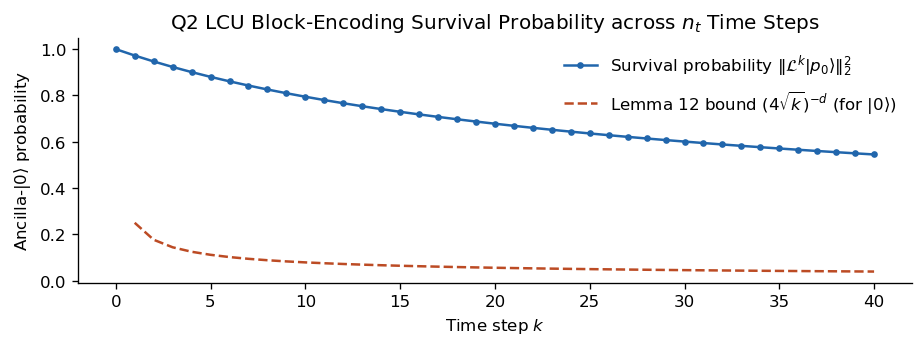

In [32]:
q2_2b = qs.q2_stage2b_evolve_and_amplify(disc_1d, q2_1, q2_2a)
print("=== Q2 Stage 2b: nt-Step LCU Evolution & Amplitude Amplification ===")
print(f"Final survival norm ||L^nt |p0>||_2  = {q2_2b['norm_final']:.6f}")
print(f"Post-selection prob P_success       = {q2_2b['postselect_prob']:.6f}")
print(f"Amplitude Amplification rounds      = {q2_2b['aa_rounds']}")
print(f"|||p_Q2> - L^nt|p0>/||L^nt|p0>|| ||_2 = {q2_2b['state_err_vs_Lnt']:.3e}")

fig, ax = plt.subplots(figsize=(7.8, 3.0))
ax.plot(np.arange(disc_1d.nt + 1), q2_2b["norm_history"] ** 2, "o-", ms=3, color="#2166ac", label=r"Survival probability $\|\mathcal{L}^k |p_0\rangle\|_2^2$")
ax.plot(np.arange(1, disc_1d.nt + 1), disc_1d.spectra["lemma12_lower_bound"], "--", color="#bc4b24", label=r"Lemma 12 bound $(4\sqrt{k})^{-d}$ (for $|0\rangle$)")
ax.set_xlabel("Time step $k$")
ax.set_ylabel("Ancilla-$|0\\rangle$ probability")
ax.set_title("Q2 LCU Block-Encoding Survival Probability across $n_t$ Time Steps")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

#### Q2 Stage 3: Multidimensional Measurement Protocol (Fig. 6 Stage 3)

In [33]:
q2_3 = qs.q2_stage3_measurement(disc_1d, q2_2b, seed=313)
print("=== Q2 Stage 3: Theorem 16 Measurement Output ===")
print(f"||p_Q2 - p_tilde||_inf = {q2_3['err_inf_vs_ptilde']:.6f} (<= eps_q = {config_1d.eps_q})")
print(f"||p_Q2 - p_exact||_inf = {q2_3['err_inf_vs_exact']:.6f} (<= eps_c + eps_q = {q2_3['total_eps_bound']:.2f})")

=== Q2 Stage 3: Theorem 16 Measurement Output ===
||p_Q2 - p_tilde||_inf = 0.049507 (<= eps_q = 0.05)
||p_Q2 - p_exact||_inf = 0.050011 (<= eps_c + eps_q = 0.10)


### Q3 — Quantum Random Walk Fast-Forwarding (Fig. 7, Theorems 20 & 21)
#### Q3 Stage 1: Initialize Spatial Quantum State $|p_0\rangle$

In [34]:
q3_1 = qs.q3_stage1_initialize_state(disc_1d)
print("=== Q3 Stage 1: Initialize |p0> ===")
print(f"Spatial qubits q_space = {q3_1['q_space']}, |||p0>||_2 = {np.linalg.norm(q3_1['ket_p0']):.15f}")

=== Q3 Stage 1: Initialize |p0> ===
Spatial qubits q_space = 5, |||p0>||_2 = 1.000000000000001


#### Q3 Stage 2a: Compute Chebyshev Walk Cutoff $M_{\text{walk}} = O(\sqrt{n_t \log(\dots)})$ (Theorem 20, Eq. 80)

In [35]:
q3_2a = qs.q3_stage2a_build_quantum_walk_chebyshev_lcu(disc_1d, q3_1)
print("=== Q3 Stage 2a: Apers-Sarlette Fast-Forwarding Parameters ===")
print(f"Classical steps nt        = {q3_2a['nt']}")
print(f"Fast-forwarded steps M_wk = {q3_2a['M_walk']} (quadratic speedup {q3_2a['speedup_ratio_nt_over_M']:.2f}x fewer steps)")
print(f"||L^nt |p0>||_2           = {q3_2a['norm_Lnt_ket']:.6f}")
print(f"Chebyshev LCU weight sum  = {q3_2a['cheb_l1_weight']:.6f}")

=== Q3 Stage 2a: Apers-Sarlette Fast-Forwarding Parameters ===
Classical steps nt        = 40
Fast-forwarded steps M_wk = 18 (quadratic speedup 2.22x fewer steps)
||L^nt |p0>||_2           = 0.738284
Chebyshev LCU weight sum  = 0.997779


#### Q3 Stage 2b: Evaluate $M_{\text{walk}}$-Step Quantum Walk & Verify Eq. (79)

=== Q3 Stage 2b: Fast-Forwarded Walk Operator (Qiskit Block-Encoding) ===
Qiskit circuit qubits         = 6
Eq. (79) |||p_Q3> - |p_ref>||_2 = 1.791811e-02 <= eta (0.05) -> True
Amplitude Amplification rounds= 1


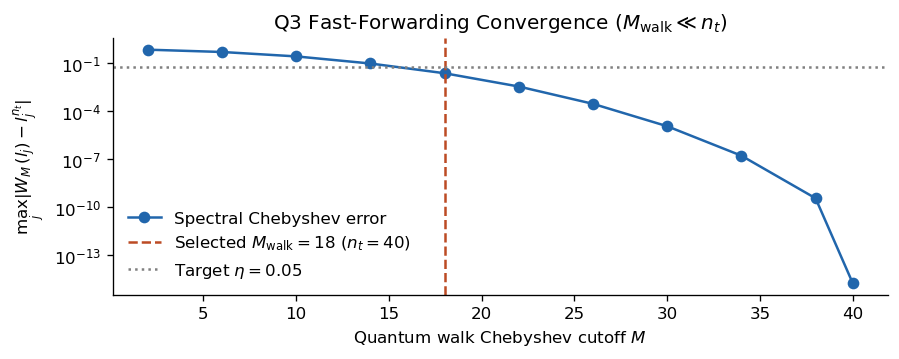

In [36]:
q3_2b = qs.q3_stage2b_fast_forward_and_amplify(disc_1d, q3_1, q3_2a)
print("=== Q3 Stage 2b: Fast-Forwarded Walk Operator (Qiskit Block-Encoding) ===")
print(f"Qiskit circuit qubits         = {q3_2b['circuit'].num_qubits}")
print(f"Eq. (79) |||p_Q3> - |p_ref>||_2 = {q3_2b['eq79_state_err']:.6e} <= eta ({q3_2a['eta']}) -> {q3_2b['eq79_bound_ok']}")
print(f"Amplitude Amplification rounds= {q3_2b['aa_rounds']}")

fig, ax = plt.subplots(figsize=(7.6, 3.1))
ax.semilogy(q3_2b["m_sweep"], np.maximum(q3_2b["sweep_errs"], 1e-16), "o-", color="#2166ac", label="Spectral Chebyshev error")
ax.axvline(q3_2a["M_walk"], ls="--", color="#bc4b24", label=rf"Selected $M_{{\mathrm{{walk}}}} = {q3_2a['M_walk']}$ ($n_t = {disc_1d.nt}$)")
ax.axhline(q3_2a["eta"], ls=":", color="gray", label=rf"Target $\eta = {q3_2a['eta']}$")
ax.set_xlabel("Quantum walk Chebyshev cutoff $M$")
ax.set_ylabel(r"$\max_j |W_M(l_j) - l_j^{n_t}|$")
ax.set_title("Q3 Fast-Forwarding Convergence ($M_{\\mathrm{walk}} \\ll n_t$)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

#### Q3 Stage 3: Multidimensional Measurement Protocol (Fig. 7 Stage 3)

In [37]:
q3_3 = qs.q3_stage3_measurement(disc_1d, q3_2b, seed=313)
print("=== Q3 Stage 3: Theorem 16 Measurement Output ===")
print(f"||p_Q3 - p_tilde||_inf = {q3_3['err_inf_vs_ptilde']:.6f} (<= eps_q = {config_1d.eps_q})")
print(f"||p_Q3 - p_exact||_inf = {q3_3['err_inf_vs_exact']:.6f} (<= eps_c + eps_q = {q3_3['total_eps_bound']:.2f})")

=== Q3 Stage 3: Theorem 16 Measurement Output ===
||p_Q3 - p_tilde||_inf = 0.049628 (<= eps_q = 0.05)
||p_Q3 - p_exact||_inf = 0.050011 (<= eps_c + eps_q = 0.10)


### Q4 — Quantum Diagonalization by QFT (Fig. 8, Theorem 22)
#### Q4 Stage 1: Initialize Spatial State $|p_0\rangle$ & Ancilla $|0\rangle$ in Qiskit

In [38]:
q4_1 = qs.q4_stage1_initialize_state(disc_1d)
print("=== Q4 Stage 1: Qiskit Circuit State Initialization ===")
print(f"Spatial qubits q_space = {q4_1['q_space']} (+ 1 ancilla = {q4_1['circuit_s1'].num_qubits} total)")
print(f"Uses native QFTGate?   = {q4_1['uses_native_QFTGate']}")
print(f"|||p0>_Qiskit - |p0>||_2 = {np.linalg.norm(q4_1['ket_p0_qiskit'] - disc_1d.ket_p0):.3e}")

=== Q4 Stage 1: Qiskit Circuit State Initialization ===
Spatial qubits q_space = 5 (+ 1 ancilla = 6 total)
Uses native QFTGate?   = True
|||p0>_Qiskit - |p0>||_2 = 1.072e-12


#### Q4 Stage 2: Apply QFT Layer (`QFTGate.inverse()`) $|p_0\rangle \mapsto |\psi_0\rangle$ (Eq. 95)

In [39]:
q4_2 = qs.q4_stage2_apply_qft(disc_1d, q4_1)
print("=== Q4 Stage 2: Forward QFT Layer ===")
print(f"|||psi0>||_2              = {q4_2['psi0_l2_norm']:.15f}")
print(f"max |psi0_Qiskit - FFT|   = {q4_2['qft_vs_fft_err']:.3e}")

=== Q4 Stage 2: Forward QFT Layer ===
|||psi0>||_2              = 1.000000000000000
max |psi0_Qiskit - FFT|   = 1.927e-13


#### Q4 Stage 3a: Precompute Eigenvalues $\tilde{l}_{\mathbf{j}}^{n_t}$ up to $\delta = \epsilon_c$ (Lemma 9)

In [40]:
q4_3a = qs.q4_stage3a_calculate_eigenvalues(disc_1d)
print("=== Q4 Stage 3a: Precompute Eigenvalues (Lemma 9) ===")
print(f"Taylor order K                     = {q4_3a['taylor_terms_K']}")
print(f"max |Lambda_tilde^nt - Lambda^nt|  = {q4_3a['eig_max_err_vs_exact']:.3e}")
print(f"Magnitude range [min, max]         = [{np.min(q4_3a['magnitudes']):.6f}, {np.max(q4_3a['magnitudes']):.6f}]")

=== Q4 Stage 3a: Precompute Eigenvalues (Lemma 9) ===
Taylor order K                     = 10
max |Lambda_tilde^nt - Lambda^nt|  = 1.261e-03
Magnitude range [min, max]         = [0.000007, 1.000000]


#### Q4 Stage 3b & 3c: Ancilla Rotation (`DiagonalGate` + `UCRYGate`, Eq. 96) & Amplitude Amplification

In [41]:
q4_3bc = qs.q4_stage3bc_ancilla_rotation_and_amplitude_amplification(
    disc_1d, q4_1, q4_2, q4_3a
)
print("=== Q4 Stages 3b & 3c: Ancilla Rotation & Amplitude Amplification ===")
print(f"Full dilated state norm |||Psi_rot>||_2 = {q4_3bc['unitarity_norm']:.15f} (unitary check)")
print(f"Ancilla-|0> probability P(0)            = {q4_3bc['P_zero']:.6f}")
print(f"Amplitude Amplification rounds N_AA     = {q4_3bc['aa_rounds']}")

=== Q4 Stages 3b & 3c: Ancilla Rotation & Amplitude Amplification ===
Full dilated state norm |||Psi_rot>||_2 = 1.000000000000001 (unitary check)
Ancilla-|0> probability P(0)            = 0.545069
Amplitude Amplification rounds N_AA     = 1


#### Q4 Stage 4: Apply Inverse QFT (`QFTGate`) & Transpile Circuit Resources (`["u", "cx"]`)

In [42]:
q4_4 = qs.q4_stage4_apply_iqft(disc_1d, q4_1, q4_3bc)
print("=== Q4 Stage 4: Inverse QFT & Compiled Circuit Resources ===")
print(f"Total qubits       = {q4_4['num_qubits']}")
print(f"Compiled depth     = {q4_4['compiled_depth']}")
print(f"Total basis gates  = {q4_4['compiled_size']}, CX gates = {q4_4['compiled_cx_count']}")
print(f"Ancilla-|0> P(0)   = {q4_4['P_zero']:.6f}")
print(f"|||p_Q4> - |L^nt p0>||_2 = {q4_4['state_err_vs_Lnt']:.6e}")
print("\nHigh-level Q4 QuantumCircuit diagram:")
print(q4_4["circuit_full"].draw(output="text"))

=== Q4 Stage 4: Inverse QFT & Compiled Circuit Resources ===
Total qubits       = 6
Compiled depth     = 221
Total basis gates  = 304, CX gates = 140
Ancilla-|0> P(0)   = 0.545069
|||p_Q4> - |L^nt p0>||_2 = 6.945587e-04

High-level Q4 QuantumCircuit diagram:
     »
q_0: »
     »
q_1: »
     »
q_2: »
     »
q_3: »
     »
q_4: »
     »
q_5: »
     »
«     ┌──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐»
«q_0: ┤0                                                                                                                                                                                                                             ├»
«     │                                                                                                                                                                                   

#### Q4 Stage 5: Multidimensional Measurement Protocol (Fig. 8 Stage 5)

In [43]:
q4_5 = qs.q4_stage5_measurement(disc_1d, q4_4, seed=313)
print("=== Q4 Stage 5: Theorem 16 Measurement Output ===")
print(f"||p_Q4 - p_tilde||_inf = {q4_5['err_inf_vs_ptilde']:.6f} (<= eps_q = {config_1d.eps_q})")
print(f"||p_Q4 - p_exact||_inf = {q4_5['err_inf_vs_exact']:.6f} (<= eps_c + eps_q = {q4_5['total_eps_bound']:.2f})")

=== Q4 Stage 5: Theorem 16 Measurement Output ===
||p_Q4 - p_tilde||_inf = 0.049463 (<= eps_q = 0.05)
||p_Q4 - p_exact||_inf = 0.050011 (<= eps_c + eps_q = 0.10)


---
## Step 5: Master Comparison of All 8 Algorithms (1D, 2D, and Quantum Advantage Scaling)
Compares all 4 Classical (`C1`–`C4`) and 4 Quantum (`Q1`–`Q4`) implementations on both 1D and 2D test cases, verifies $\|\tilde{\tilde{\mathbf{p}}} - \mathbf{p}_{\text{exact}}\|_\infty \le \epsilon_c + \epsilon_q$, and plots the asymptotic **Table I / Table III** complexity crossover (Eq. 1 & Eq. 108).

=== MASTER 1D ACCURACY TABLE (eps_c = 0.05, eps_q = 0.05, total eps = 0.10) ===
  C1: Classical Linear (CG)    | ||p - p_disc||_inf = 0.0019 | ||p - p_exact||_inf = 0.0045
  C2: Classical Time Evol.     | ||p - p_disc||_inf = 0.0000 | ||p - p_exact||_inf = 0.0043
  C3: Classical Random Walk    | ||p - p_disc||_inf = 0.0008 | ||p - p_exact||_inf = 0.0043
  C4: Classical FFT Diag.      | ||p - p_disc||_inf = 0.0000 | ||p - p_exact||_inf = 0.0043
  Q1: Quantum Linear (HHL)     | ||p - p_disc||_inf = 0.0495 | ||p - p_exact||_inf = 0.0500
  Q2: Quantum Time Evol (LCU)  | ||p - p_disc||_inf = 0.0495 | ||p - p_exact||_inf = 0.0500
  Q3: Quantum Random Walk      | ||p - p_disc||_inf = 0.0495 | ||p - p_exact||_inf = 0.0500
  Q4: Quantum QFT Diag.        | ||p - p_disc||_inf = 0.0495 | ||p - p_exact||_inf = 0.0500

=== MASTER 2D ACCURACY TABLE (d=2, nx=12, nt=20, eps_c=0.05, eps_q=0.03, eps=0.08) ===
  C1: Classical Linear (CG)    | ||p - p_disc||_inf = 0.0011 | ||p - p_exact||_inf = 0.0077
  C2

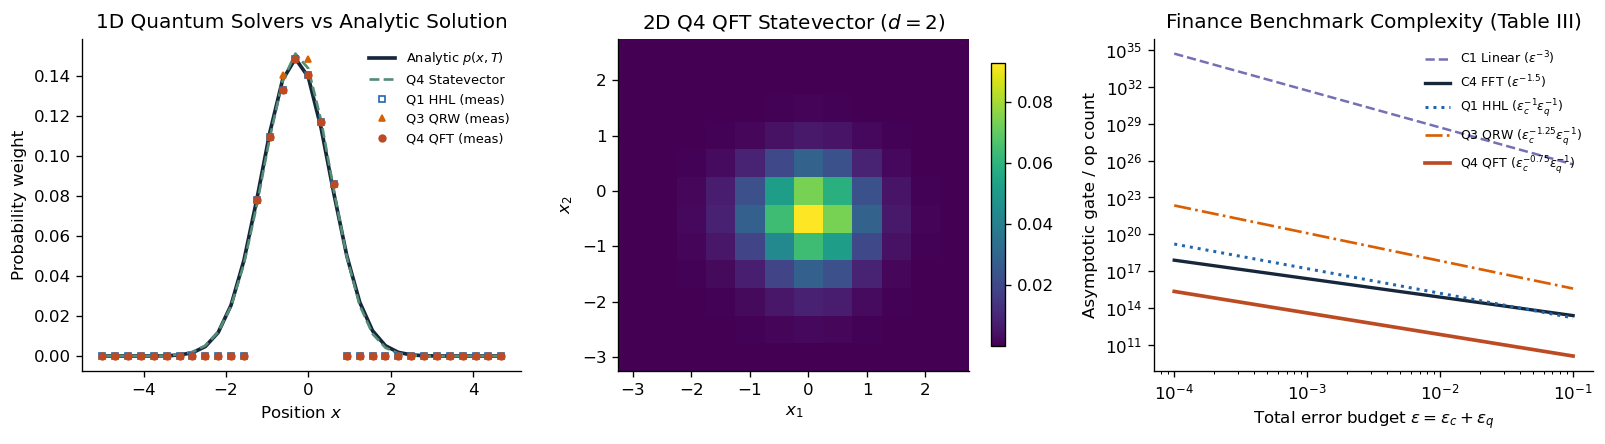

In [44]:
# Run all 4 Quantum Solvers on 2D test case (d=2, nx=12, nt=20, eps_c=0.05, eps_q=0.03)
res_q_2d = qs.run_all_quantum_solvers(disc_2d, seed=313)

print("=== MASTER 1D ACCURACY TABLE (eps_c = 0.05, eps_q = 0.05, total eps = 0.10) ===")
rows_1d = [
    ("C1: Classical Linear (CG)",   c1_s3["p_T"],            c1_s3["err_inf_vs_exact"]),
    ("C2: Classical Time Evol.",    c2_s2["p_T"],            c2_s2["err_inf_vs_exact"]),
    ("C3: Classical Random Walk",   c3_s3["p_T_empirical"],  c3_s3["err_inf_vs_exact_by_M"][c3_s3["finest_M"]]),
    ("C4: Classical FFT Diag.",     c4_s4["p_T"],            c4_s4["err_inf_vs_exact"]),
    ("Q1: Quantum Linear (HHL)",    q1_3["p_T"],             q1_3["err_inf_vs_exact"]),
    ("Q2: Quantum Time Evol (LCU)", q2_3["p_T"],             q2_3["err_inf_vs_exact"]),
    ("Q3: Quantum Random Walk",     q3_3["p_T"],             q3_3["err_inf_vs_exact"]),
    ("Q4: Quantum QFT Diag.",       q4_5["p_T"],             q4_5["err_inf_vs_exact"]),
]
for name, p_vec, err_ex in rows_1d:
    diff_disc = float(np.max(np.abs(p_vec - c2_s2["p_T"])))
    print(f"  {name:28s} | ||p - p_disc||_inf = {diff_disc:.4f} | ||p - p_exact||_inf = {err_ex:.4f}")

print("\n=== MASTER 2D ACCURACY TABLE (d=2, nx=12, nt=20, eps_c=0.05, eps_q=0.03, eps=0.08) ===")
rows_2d = [
    ("C1: Classical Linear (CG)",   res_c_2d["C1_linear_cg"]["p_T"]),
    ("C2: Classical Time Evol.",    res_c_2d["C2_time_evolution"]["p_T"]),
    ("C3: Classical Random Walk",   res_c_2d["C3_random_walk"]["p_T_empirical"]),
    ("C4: Classical FFT Diag.",     res_c_2d["C4_fft"]["p_T"]),
    ("Q1: Quantum Linear (HHL)",    res_q_2d["Q1_linear_hhl"]["s3"]["p_T"]),
    ("Q2: Quantum Time Evol (LCU)", res_q_2d["Q2_time_lcu"]["s3"]["p_T"]),
    ("Q3: Quantum Random Walk",     res_q_2d["Q3_random_walk"]["s3"]["p_T"]),
    ("Q4: Quantum QFT Diag.",       res_q_2d["Q4_qft_diag"]["s5"]["p_T"]),
]
for name, p_vec in rows_2d:
    diff_disc2 = float(np.max(np.abs(p_vec - res_c_2d["C2_time_evolution"]["p_T"])))
    err_ex2 = float(np.max(np.abs(p_vec - disc_2d.p_exact_T)))
    print(f"  {name:28s} | ||p - p_disc||_inf = {diff_disc2:.4f} | ||p - p_exact||_inf = {err_ex2:.4f}")

# Multi-panel final visual comparison
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))

# Panel 1: 1D Quantum Readouts & Q4 Statevector vs Analytic + C4 FFT
axes[0].plot(disc_1d.x_1d, disc_1d.p_exact_T, "-", color="#16263b", lw=2.2, label="Analytic $p(x,T)$")
axes[0].plot(disc_1d.x_1d, q4_4["p_T_statevector_exact"], "--", color="#528d75", lw=1.6, label="Q4 Statevector")
axes[0].plot(disc_1d.x_1d, q1_3["p_T"], "s", ms=4, fillstyle="none", color="#2166ac", label="Q1 HHL (meas)")
axes[0].plot(disc_1d.x_1d, q3_3["p_T"], "^", ms=4, color="#d95f02", label="Q3 QRW (meas)")
axes[0].plot(disc_1d.x_1d, q4_5["p_T"], "o", ms=4, color="#bc4b24", label="Q4 QFT (meas)")
axes[0].set_xlabel("Position $x$")
axes[0].set_ylabel("Probability weight")
axes[0].set_title("1D Quantum Solvers vs Analytic Solution")
axes[0].legend(frameon=False, fontsize=7.8)

# Panel 2: 2D Quantum QFT Statevector Reconstruction
X2, Y2 = np.meshgrid(disc_2d.x_1d, disc_2d.x_1d, indexing="ij")
q4_sv_2d = res_q_2d["Q4_qft_diag"]["s4"]["p_T_statevector_exact"].reshape(disc_2d.nx, disc_2d.nx)
im = axes[1].pcolormesh(X2, Y2, q4_sv_2d, shading="auto", cmap="viridis")
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
axes[1].set_title("2D Q4 QFT Statevector ($d=2$)")
fig.colorbar(im, ax=axes[1], shrink=0.85)

# Panel 3: Finance Benchmark Complexity Scaling vs total epsilon (Table III)
eps_vals = np.logspace(-4, -1, 50)
eps_c_split = 0.5 * eps_vals
eps_q_split = 0.5 * eps_vals
axes[2].loglog(eps_vals, fin["classical_linear_prefactor"] / (eps_vals**3), "--", color="#7570b3", label="C1 Linear ($\\epsilon^{-3}$)")
axes[2].loglog(eps_vals, fin["classical_fft_prefactor"] / (eps_vals**1.5), "-", lw=2, color="#16263b", label="C4 FFT ($\\epsilon^{-1.5}$)")
axes[2].loglog(eps_vals, fin["quantum_linear_prefactor"] / (eps_c_split * eps_q_split), ":", lw=1.8, color="#2166ac", label="Q1 HHL ($\\epsilon_c^{-1}\\epsilon_q^{-1}$)")
axes[2].loglog(eps_vals, fin["quantum_rw_prefactor"] / ((eps_c_split**1.25) * eps_q_split), "-.", lw=1.6, color="#d95f02", label="Q3 QRW ($\\epsilon_c^{-1.25}\\epsilon_q^{-1}$)")
axes[2].loglog(eps_vals, fin["quantum_qft_prefactor"] / ((eps_c_split**0.75) * eps_q_split), "-", lw=2.2, color="#bc4b24", label="Q4 QFT ($\\epsilon_c^{-0.75}\\epsilon_q^{-1}$)")
axes[2].set_xlabel(r"Total error budget $\epsilon = \epsilon_c + \epsilon_q$")
axes[2].set_ylabel("Asymptotic gate / op count")
axes[2].set_title("Finance Benchmark Complexity (Table III)")
axes[2].legend(frameon=False, fontsize=7.5)

plt.tight_layout()
plt.show()